# Experiments for HeartSteps DNN

In [1101]:
# for code imports, change working directory to src
# RUN ONCE per kernel instance
%cd ../src

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src


In [1102]:
%pip freeze

^C
Note: you may need to restart the kernel to use updated packages.


asttokens==2.4.1
clarabel==0.9.0
cloudpickle==3.0.0
colorama==0.4.6
comm==0.2.2
contourpy==1.2.1
cvxopt==1.3.2
cvxpy==1.5.2
cycler==0.12.1
debugpy==1.8.2
decorator==5.1.1
ecos==2.0.14
executing==2.0.1
fancyimpute==0.7.0
fonttools==4.53.1
future==1.0.0
hyperopt==0.2.7
iniconfig==2.0.0
ipykernel==6.29.5
ipython==8.26.0
jedi==0.19.1
joblib==1.4.2
jupyter_client==8.6.2
jupyter_core==5.7.2
kiwisolver==1.4.5
knnimpute==0.1.0
matplotlib==3.9.1
matplotlib-inline==0.1.7
nest-asyncio==1.6.0
networkx==3.3
nose==1.3.7
numpy==2.0.0
osqp==0.6.7.post0
packaging==24.1
pandas==2.2.2
parso==0.8.4
pillow==10.4.0
platformdirs==4.2.2
pluggy==1.5.0
prompt_toolkit==3.0.47
psutil==6.0.0
pure-eval==0.2.2
py4j==0.10.9.7
Pygments==2.18.0
pyparsing==3.1.2
pytest==8.2.2
python-dateutil==2.9.0.post0
pytz==2024.1
pywin32==306
pyzmq==26.0.3
qdldl==0.1.7.post4
scikit-learn==1.5.1
scipy==1.14.0
scs==3.2.6
seaborn==0.13.2
six==1.16.0
stack-data==0.6.3
threadpoolctl==3.5.0
tornado==6.4.1
tqdm==4.66.4
traitlets==5.14.3
ty

In [ ]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [1299]:
# local modules
import dnn
import cross_validate_dnn as cv_dnn
import scaler_methods

# packages
import numpy as np
import pandas as pd
from itertools import chain
import itertools
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt
import matplotlib as mpl
import math


## Plot settings

In [ ]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 15
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = label_size


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']


## Load data 

In [1302]:
# set up
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")
M_hs = np.load("../data_checkpoints/heartsteps_data.npy")

M_hs_unsorted = M_hs.copy()

# required for Wasserstein
M_hs = np.sort(M_hs, axis = -1)

# dimension of the data is 1
M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape


In [1192]:
diffs = dnn.get_col_differences(M_hs, A_hs, metric = "wasserstein2", kernel = "square")

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:262: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:265: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)


In [1303]:
np.nanmax(diffs[~np.isinf(diffs)])

np.float64(629039.75)

In [1304]:
## LOG TRANSFORM HERE!!!!!

M_hs = np.log(M_hs + 1)

In [1313]:
M_hs.shape

(37, 200, 12, 1)

## Estimates

In [1314]:
# for each row, search for eta, estimate the row
# this time, split by users rather than time
split_A = np.split(A_hs, 2, axis = 1)
split_M = np.split(M_hs, 2, axis = 1)

width = len(A_hs[0])
ws2_estimates = np.full([N, T, n], np.nan)

mmd_estimates_exp = [None] * N
mmd_estimates_sq = [None] * N

nn_ws2 = np.full([N, T], np.nan)
nn_mmd_exp = np.full([N, T], np.nan)
nn_mmd_sq = np.full([N, T], np.nan)

eta_stars = np.full([37, 6], np.nan)

neighbors_ws2 = [None] * N

neighbors_mmd_exp = [None] * N

neighbors_mmd_sq = [None] * N

all_trials = np.full([37, 6], None, dtype = object)

for i in range(len(A_hs)):
  print("User " + str(i))
  # sample split
  dist_A = A_hs.copy()
  dist_A[i] = 0

  wasserstein_diffs = dnn.get_col_differences(M_hs, dist_A, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "exponential")
  mmd_sq_diffs = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "square")


  s_ws2 = np.split(wasserstein_diffs, 2, axis = 0)
  diffs_ws2_front = np.split(s_ws2[0], 2, axis = 1)[0]
  diffs_ws2_back = np.split(s_ws2[1], 2, axis = 1)[1]

  s_mmd_exp = np.split(mmd_exp_diffs, 2, axis = 0)
  diffs_mmd_exp_front = np.split(s_mmd_exp[0], 2, axis = 1)[0]
  diffs_mmd_exp_back = np.split(s_mmd_exp[1], 2, axis = 1)[1]

  s_mmd_sq = np.split(mmd_sq_diffs, 2, axis = 0)
  diffs_mmd_sq_front = np.split(s_mmd_sq[0], 2, axis = 1)[0]
  diffs_mmd_sq_back = np.split(s_mmd_sq[1], 2, axis = 1)[1]

  
  # TWO eta searches per row, one using the front half
  # the other using the back half 

  front_A_hs = split_A[0]
  back_A_hs = split_A[1]
  front_M_hs = split_M[0]
  back_M_hs = split_M[1]

  

  eta_star_ws2_front, tr_ws2_front = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_ws2_front, dnn.estimate_row, 
                                         metric="wasserstein2", 
                                         range_min = 0, range_max = 100)
  eta_stars[i, 0] = eta_star_ws2_front
  all_trials[i, 0] = tr_ws2_front

  eta_star_ws2_back, tr_ws2_back = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_ws2_back, dnn.estimate_row,
                                        metric = "wasserstein2",
                                        range_min = 0, range_max = 100)
  eta_stars[i, 1] = eta_star_ws2_back
  all_trials[i, 1] = tr_ws2_back
  eta_star_mmd_exp_front, tr_mmd_exp_front = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_mmd_exp_front, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars[i, 2] = eta_star_mmd_exp_front
  all_trials[i, 2] = tr_mmd_exp_front
  eta_star_mmd_exp_back, tr_mmd_exp_back = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_mmd_exp_back, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  all_trials[i, 3] = tr_mmd_exp_back
  eta_stars[i, 3] = eta_star_mmd_exp_back
  eta_star_mmd_sq_front, tr_mmd_sq_front = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_mmd_sq_front, dnn.estimate_row, 
                                         metric="mmd", kernel = "square", 
                                         range_min = 0, range_max = 2500)
  eta_stars[i, 4] = eta_star_mmd_sq_front
  all_trials[i, 4] = tr_mmd_sq_front
  eta_star_mmd_sq_back, tr_mmd_sq_back = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_mmd_sq_back, dnn.estimate_row,
                                        metric = "mmd", kernel = "square",
                                        range_min = 0, range_max = 2500)
  eta_stars[i, 5] = eta_star_mmd_sq_back
  all_trials[i, 5] = tr_mmd_sq_back
  # estimate first half using eta from second
  test_inds = np.nonzero(A_hs[i] == 1)[0]
  front_test_inds = test_inds[test_inds < (width / 2)]
  back_test_inds = test_inds[test_inds >= (width / 2)]

  print("Estimating unit " + str(i))

  estimate_front_ws2, nn_front_ws2, neighbors_front_ws2 = dnn.estimate_row(M_hs, A_hs, i, front_test_inds, 
                                        wasserstein_diffs, eta_star_ws2_back, 
                                        "wasserstein2", ret_nn = True)
  estimate_front_ws2 = estimate_front_ws2[:T // 2]
  nn_front_ws2 = nn_front_ws2[:T//2]
  neighbors_front_ws2 = neighbors_front_ws2[:T // 2]

  estimate_back_ws2, nn_back_ws2, neighbors_back_ws2 = dnn.estimate_row(M_hs, A_hs, i, back_test_inds, 
                                        wasserstein_diffs, eta_star_ws2_front, 
                                        "wasserstein2", ret_nn = True)
  estimate_back_ws2 = estimate_back_ws2[T // 2 : ]
  nn_back_ws2 = nn_back_ws2[T//2 : ]
  neighbors_back_ws2 = neighbors_back_ws2[T // 2 :]

  estimate_front_mmd_exp, nn_front_mmd_exp, neighbors_front_mmd_exp = dnn.estimate_row(M_hs, A_hs, i, front_test_inds,
                                            mmd_exp_diffs, eta_star_mmd_exp_back,
                                            "mmd", ret_nn = True)
  estimate_front_mmd_exp = estimate_front_mmd_exp[:T // 2 ]
  nn_front_mmd_exp = nn_front_mmd_exp[:T // 2 ]
  neighbors_front_mmd_exp = neighbors_front_mmd_exp[:T // 2]

  estimate_back_mmd_exp, nn_back_mmd_exp, neighbors_back_mmd_exp = dnn.estimate_row(M_hs, A_hs, i, back_test_inds,
                                            mmd_exp_diffs, eta_star_mmd_exp_front,
                                            "mmd", ret_nn = True)
  estimate_back_mmd_exp = estimate_back_mmd_exp[T // 2 :]
  nn_back_mmd_exp = nn_back_mmd_exp[T // 2 :]
  neighbors_back_mmd_exp = neighbors_back_mmd_exp[T // 2 :]

  estimate_front_mmd_sq, nn_front_mmd_sq, neighbors_front_mmd_sq = dnn.estimate_row(M_hs, A_hs, i, front_test_inds,
                                            mmd_sq_diffs, eta_star_mmd_sq_back,
                                            "mmd", ret_nn = True)
  estimate_front_mmd_sq = estimate_front_mmd_sq[:T // 2]
  nn_front_mmd_sq = nn_front_mmd_sq[:T//2]
  neighbors_front_mmd_sq = neighbors_front_mmd_sq[: T // 2]

  estimate_back_mmd_sq, nn_back_mmd_sq, neighbors_back_mmd_sq = dnn.estimate_row(M_hs, A_hs, i, back_test_inds,
                                            mmd_sq_diffs, eta_star_mmd_sq_front,
                                            "mmd", ret_nn = True)
  estimate_back_mmd_sq = estimate_back_mmd_sq[T // 2 :]
  nn_back_mmd_sq = nn_back_mmd_sq[T // 2 :]
  neighbors_back_mmd_sq = neighbors_back_mmd_sq[T // 2 : ]
  
  # concat estimates together
  est_row_ws2 = np.concatenate((estimate_front_ws2, estimate_back_ws2), axis = 0)
  est_row_mmd_exp = estimate_front_mmd_exp + estimate_back_mmd_exp
  est_row_mmd_sq = estimate_front_mmd_sq + estimate_back_mmd_sq

  row_nn_ws2 = np.concatenate((nn_front_ws2, nn_back_ws2), axis = 0)
  row_nn_mmd_exp = np.concatenate((nn_front_mmd_exp, nn_back_mmd_exp), axis = 0)
  row_nn_mmd_sq = np.concatenate((nn_front_mmd_sq, nn_back_mmd_sq), axis = 0)

  row_neighbors_ws2 = neighbors_front_ws2 + neighbors_back_ws2
  row_neighbors_mmd_exp = neighbors_front_mmd_exp + neighbors_back_mmd_exp
  row_neighbors_mmd_sq = neighbors_front_mmd_sq + neighbors_back_mmd_sq

  neighbors_ws2[i] = row_neighbors_ws2
  neighbors_mmd_exp[i] = row_neighbors_mmd_exp
  neighbors_mmd_sq[i] = row_neighbors_mmd_sq

  ws2_estimates[i] = est_row_ws2
  mmd_estimates_exp[i] = est_row_mmd_exp
  mmd_estimates_sq[i] = est_row_mmd_sq

  nn_ws2[i] = row_nn_ws2
  nn_mmd_exp[i] = row_nn_mmd_exp
  nn_mmd_sq[i] = row_nn_mmd_sq




  

  
  
  

User 0


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:262: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:265: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:109: RuntimeWarning: Mean of empty slice
  val = np.nanmean(val_all)


 65%|██████▌   | 130/200 [00:06<00:03, 22.98trial/s, best loss: 0.17582599780721372]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:45: RuntimeWarning: invalid value encountered in matmul
  XY = np.matmul(dat1, np.transpose(dat2)) # m by n matrix with x_i^Ty_j

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:57: RuntimeWarning: invalid value encountered in subtract
  kXX = np.exp( -0.5*( dXX_mm + np.transpose(dXX_mm) - 2*XX ) )



 20%|█▉        | 39/200 [00:00<00:02, 80.01trial/s, best loss: 26.207376978884035]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:62: RuntimeWarning: invalid value encountered in scalar subtract
  val = (np.sum(kXX) - np.sum(np.diag(kXX)))/(m*(m - 1)) + (np.sum(kYY) - np.sum(np.diag(kYY)))/(n*(n - 1)) - 2*np.sum(kXY)/(n*m)



100%|██████████| 200/200 [00:02<00:00, 69.96trial/s, best loss: 24.501659758110748]
Estimating unit 0
User 1
100%|██████████| 200/200 [00:01<00:00, 104.17trial/s, best loss: 35.395037490982375]
Estimating unit 1
User 2
100%|██████████| 200/200 [00:02<00:00, 98.55trial/s, best loss: 14.854328782537422] 
Estimating unit 2
User 3
100%|██████████| 200/200 [00:02<00:00, 82.91trial/s, best loss: 47.67574403957417] 
Estimating unit 3
User 4
100%|██████████| 200/200 [00:02<00:00, 82.60trial/s, best loss: 17.451945581986053]
Estimating unit 4
User 5
100%|██████████| 200/200 [00:02<00:00, 79.48trial/s, best loss: 50.57908693322956]
Estimating unit 5
User 6
100%|██████████| 200/200 [00:02<00:00, 71.59trial/s, best loss: 27.215931981724133]
Estimating unit 6
User 7
100%|██████████| 200/200 [00:04<00:00, 40.93trial/s, best loss: 7.944099147685312] 
Estimating unit 7
User 8
100%|██████████| 200/200 [00:05<00:00, 38.64trial/s, best loss: 22.090085816063628]
Estimating unit 8
User 9
100%|██████████| 2

In [ ]:
pd.DataFrame(eta_stars)

,0,1,2,3,4,5
0,22.304975,18052.399926,0.717309,0.190335,8.051113e+05,9.628474e+05
1,32629.800764,34927.544687,0.236005,0.825605,1.190670e+06,2.526171e+06
2,38935.836011,17350.395341,0.079883,0.015569,1.658286e+05,2.533213e+06
3,12.312852,19845.694744,0.082423,0.038211,4.897181e+02,2.332778e+06
4,24021.114644,13.295350,0.036022,0.024825,7.994527e+05,2.305833e+05
5,33380.923507,37677.195464,0.301339,0.263244,2.923278e+06,1.860321e+06
6,10982.892973,19647.982541,0.002878,0.056605,5.047174e+05,1.821148e+06
7,36994.566135,34751.407878,0.171854,0.125480,2.383563e+06,1.078503e+06
8,49670.554937,42878.957882,0.153569,0.127713,5.723822e+05,5.225474e+05
9,28688.090430,26304.567872,0.179091,0.807495,1.700632e+06,2.035025e+06


In [1316]:
# save estimate
np.save('ws2_estimates_v13_log.npy', ws2_estimates) 
np.save('mmd_exp_estimates_v13_log.npy', np.array(mmd_estimates_exp,dtype=object), allow_pickle=True) 
np.save('mmd_sq_estimates_v13_log.npy', np.array(mmd_estimates_sq,dtype=object), allow_pickle=True) 

np.save('ws2_nncount_v13_log.npy', nn_ws2) 
np.save('mmd_exp_nncount_v13_log.npy', nn_mmd_exp)
np.save('mmd_sq_nncount_v13_log.npy', nn_mmd_sq)

np.save('ws2_full_neighbors_v13_log.npy', np.array(neighbors_ws2, dtype = object), allow_pickle = True)
np.save('mmd_exp_full_neighbors_v13_log.npy', np.array(neighbors_mmd_exp, dtype = object), allow_pickle = True)
np.save('mmd_sq_full_neighbors_v13_log.npy', np.array(neighbors_mmd_sq, dtype = object), allow_pickle = True)


# v4 eta star has repeated square eta (bug)
np.save('eta_stars_v13_log.npy', eta_stars)
np.save('trials_v13_log.npy', all_trials)

In [1184]:
neighbors_ws2

[[None,
  (array([  4, 107, 116]),),
  None,
  None,
  (array([  1,  36,  38, 107, 113, 139, 172]),),
  None,
  (array([ 72,  96, 112]),),
  None,
  None,
  None,
  None,
  (array([92]),),
  (array([ 42,  43,  88, 109, 145]),),
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  (array([ 30,  33,  37,  38,  56,  60,  65, 106, 107, 172]),),
  None,
  None,
  None,
  None,
  (array([ 60,  92, 113, 132, 139, 145, 146, 172]),),
  None,
  None,
  (array([ 22,  37,  38,  60,  87, 113, 137, 145, 151, 174]),),
  None,
  None,
  (array([ 22,  38, 106, 147]),),
  None,
  None,
  (array([  4, 113, 137, 139, 145, 148, 172, 174]),),
  (array([ 22,  30,  38,  92, 107]),),
  (array([  4,  22,  30,  33,  37,  92, 113]),),
  None,
  None,
  None,
  (array([ 12,  43,  72,  88, 147, 148]),),
  (array([ 12,  42,  88, 109, 174]),),
  (array([ 59,  72, 106, 139, 174]),),
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  (array([ 22, 106, 137, 164

In [1141]:
len(neighbors_ws2)

37

In [1144]:
c =0 
for i in range(len(neighbors_mmd_exp)):
  for j in range(200):
    if not neighbors_mmd_exp[i][j] is None:
      c += 1
print(c)

1483


In [ ]:
pd.DataFrame(eta_stars)

,0,1,2,3,4,5
0,6.131797,7.062175,0.223749,0.192208,19.908240,22.571228
1,2.827760,13.347411,0.236340,0.857320,33.423320,144.949152
2,5.163456,0.259866,0.078441,0.041920,0.723777,4.027196
3,2.201949,1.198258,0.083800,0.038798,1.952030,4.303178
4,2.213425,10.570837,0.036130,0.023859,23.277225,1.169173
5,8.835057,10.908821,0.251753,0.264369,13.318337,40.331563
6,0.001501,13.569443,0.002935,0.054259,7.895909,6.813409
7,1.705377,7.413216,0.170359,0.124981,2.293608,3.002053
8,5.008116,5.613556,0.151673,0.127322,1.439605,12.608362
9,0.004047,17.985507,0.181145,0.751528,24.390259,17.575236


In [ ]:
np.nanmax(wasserstein_diffs[~np.isinf(wasserstein_diffs)])

np.float64(43.904340325970075)

In [ ]:
nn_mmd_exp = np.load('../data_checkpoints/mmd_exp_nncount_v2.npy', allow_pickle = True)

In [ ]:
np.nanmax(mmd_sq_diffs[~np.isinf(mmd_sq_diffs)])

np.float64(2013.8339719288417)

## NN Density

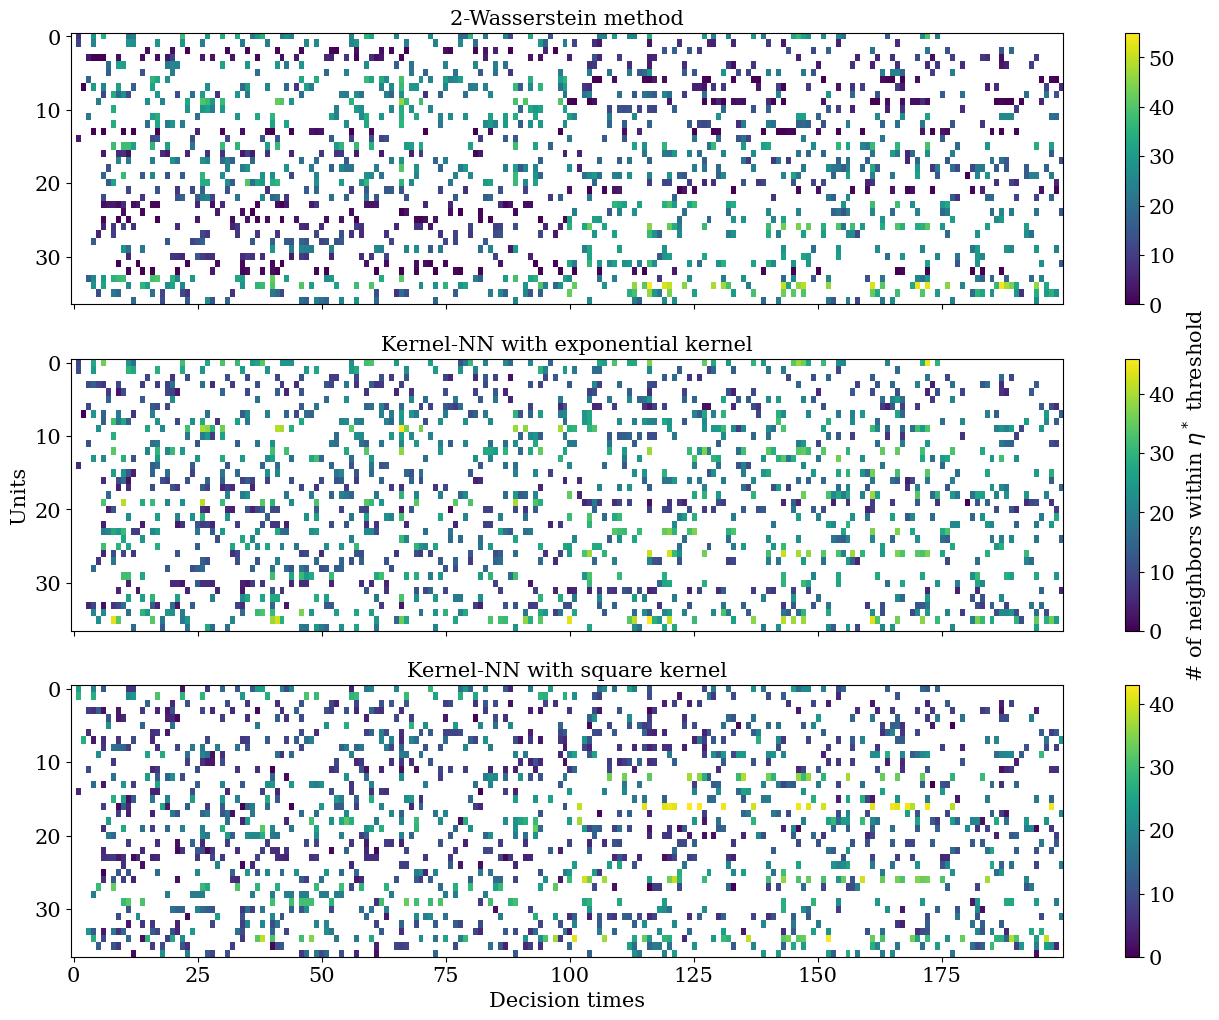

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize=(16, 12), nrows = 3)


pos1 = ax1.imshow(nn_ws2, aspect = 'auto')
pos2 = ax2.imshow(nn_mmd_exp, aspect = 'auto')
pos3 = ax3.imshow(nn_mmd_sq, aspect = 'auto')

fig.colorbar(pos1, ax = ax1)
fig.colorbar(pos2, ax = ax2, label = "# of neighbors within $\eta^*$ threshold")
fig.colorbar(pos3, ax = ax3)

ax3.set_xlabel("Decision times")
ax2.set_ylabel("Units")

ax1.get_xaxis().set_ticklabels([])
ax2.get_xaxis().set_ticklabels([])

ax1.set_title("2-Wasserstein method")
ax2.set_title("Kernel-NN with exponential kernel")
ax3.set_title("Kernel-NN with square kernel")

#fig.suptitle("2-sample Kolmogorov-Smirnov test statistic by DNN method")
plt.savefig("nn_density.pdf", bbox_inches = "tight")

In [ ]:
pd.DataFrame(eta_stars)

,0,1,2,3,4,5
0,27315.647494,14273.827171,0.131236,0.118890,1.486350e+06,1.780220e+06
1,25233.380591,32121.161560,0.069433,0.680192,2.763500e+06,2.981171e+03
2,14034.618539,277.667666,0.069096,0.017171,2.231530e+05,2.643864e+06
3,6722.518848,4845.472739,0.043877,0.022818,1.278810e+06,8.703357e+04
4,224.335496,49537.294494,0.010180,0.022065,2.620052e+05,1.305722e+05
5,1071.874236,30882.142852,0.182946,0.153007,2.024771e+06,1.105770e+06
6,40202.723768,19869.296946,0.198140,0.013633,7.378112e+05,5.104529e+05
7,36.520898,12799.392623,0.098216,0.057871,2.983701e+06,2.409755e+06
8,25942.271339,42313.062922,0.038144,0.074009,2.205073e+06,5.175422e+05
9,23383.902193,49972.994693,0.094910,0.456008,2.358859e+05,2.314807e+06


### Reproduce CDFs using NN density rather than TS-test

In [ ]:
random.seed(a=365)
high_nn_mmd_sq = np.nonzero(ks_mmd_error_sq < 0.2)
len(best_performers_mmd_sq[0])
rand_num = randrange(575)
mmd_sq_i = best_performers_mmd_sq[0][rand_num]
mmd_sq_j = best_performers_mmd_sq[1][rand_num]


In [ ]:
random.seed(a=365)
mid_performers_mmd_sq = np.nonzero((ks_mmd_error_sq > 0.2) & (ks_mmd_error_sq < 0.8))
print(len(mid_performers_mmd_sq[0]))
rand_num = randrange(895)
mmd_sq_i_mid = mid_performers_mmd_sq[0][rand_num]
mmd_sq_j_mid = mid_performers_mmd_sq[1][rand_num]

895


In [ ]:
random.seed(a=365)
poor_performers_mmd_sq = np.nonzero((ks_mmd_error_sq >= 0.8))
print(len(poor_performers_mmd_sq[0]))
rand_num = randrange(9)
mmd_i_poor_sq = poor_performers_mmd_sq[0][rand_num]
mmd_j_poor_sq = poor_performers_mmd_sq[1][rand_num]

9


In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (16, 6), ncols = 3)

ax1.ecdf(mmd_estimates_sq[mmd_sq_i][mmd_sq_j].flatten(),color = "maroon")
ax1.ecdf(M_hs_anly[mmd_sq_i, mmd_sq_j].flatten(), color="orange")
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("CDF of step count")
ax1.set_title("Unit-time with KS statistic <= 0.2")

ax2.ecdf(mmd_estimates_sq[mmd_sq_i_mid][mmd_sq_j_mid].flatten(),color = "maroon")
ax2.ecdf(M_hs_anly[mmd_sq_i_mid, mmd_sq_j_mid].flatten(), color="orange")
ax2.set_xlabel("Step count")
ax2.set_title("Unit-time with 0.2 < KS statistic < 0.8")

ax3.ecdf(mmd_estimates_sq[mmd_i_poor_sq][mmd_j_poor_sq].flatten(),color = "maroon")
ax3.ecdf(M_hs_anly[mmd_i_poor_sq, mmd_j_poor_sq].flatten(), color="orange")
ax3.set_xlabel("Step count")
ax3.set_title("Unit-time with KS statistic >= 0.8")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)

fig.suptitle("CDF of Kernel-NN$_{square}$ synthetic vs observed sample")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("cdf_mmd_sq.pdf", bbox_inches = "tight")

### SoftImpute and USVT baselines

In [ ]:
import scaler_methods

In [ ]:
# mean m_hs
M_hs_mean = np.mean(M_hs.squeeze(), axis = 2)

M_hs_log_mean = np.mean(np.log(M_hs.squeeze() + 1), axis = 2)

# std dev M_hs
M_hs_std = np.std(M_hs.squeeze(), axis = 2)
M_hs_log_std = np.std(np.log(M_hs.squeeze() + 1), axis = 2)

# variance
M_hs_var = np.var(M_hs.squeeze(), axis = 2)
M_hs_log_var = np.var(np.log(M_hs.squeeze() + 1), axis = 2)

# max
M_hs_max = np.max(M_hs.squeeze(), axis = 2)
M_hs_log_max = np.max(np.log(M_hs.squeeze() + 1), axis = 2)

# median
M_hs_median = np.median(M_hs.squeeze(), axis = 2)
M_hs_log_median = np.median(np.log(M_hs.squeeze() + 1), axis = 2)

array([[[[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [5.63121178],
         [5.84064166],
         [6.1717006 ]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [4.96284463],
         [5.6094718 ]],

        ...,

        [[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]],

        [[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]],

        [[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]]],


       [[[       nan],
         [       nan],
         [    

In [1280]:
# ASSUMING M_HS HAS ALREADY BEEN LOG-TRANSFORMED!!!!

# mean m_hs
M_hs_log_mean = np.nanmean(M_hs.squeeze(), axis = 2)

#M_hs_log_mean = np.mean(np.log(M_hs.squeeze() + 1), axis = 2)

# std dev M_hs
M_hs_log_std = np.nanstd(M_hs.squeeze(), axis = 2)
#M_hs_log_std = np.std(np.log(M_hs.squeeze() + 1), axis = 2)

# variance
M_hs_log_var = np.nanvar(M_hs.squeeze(), axis = 2)
# M_hs_log_var = np.var(np.log(M_hs.squeeze() + 1), axis = 2)

# max
M_hs_log_max = np.nanmax(M_hs.squeeze(), axis = 2)
#M_hs_log_max = np.max(np.log(M_hs.squeeze() + 1), axis = 2)

# median
M_hs_log_median = np.nanmedian(M_hs.squeeze(), axis = 2)
#M_hs_log_median = np.median(np.log(M_hs.squeeze() + 1), axis = 2)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1342113248.py:4: RuntimeWarning: Mean of empty slice
  M_hs_log_mean = np.nanmean(M_hs.squeeze(), axis = 2)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1342113248.py:13: RuntimeWarning: Degrees of freedom <= 0 for slice.
  M_hs_log_var = np.nanvar(M_hs.squeeze(), axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1342113248.py:17: RuntimeWarning: All-NaN slice encountered
  M_hs_log_max = np.nanmax(M_hs.squeeze(), axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1342113248.py:21: RuntimeWarning: All-NaN slice encountered
  M_hs_log_median = np.nanmedian(M_hs.squeeze(), axis = 2)


In [ ]:
M_hat_softimpute_mean = scaler_methods.test_estimate_softimpute(M_hs_mean, A_hs)

# havent run these yet
M_hat_softimpute_std = scaler_methods.test_estimate_softimpute(M_hs_std, A_hs)
M_hat_softimpute_var = scaler_methods.test_estimate_softimpute(M_hs_var, A_hs)
M_hat_softimpute_max = scaler_methods.test_estimate_softimpute(M_hs_max, A_hs)
M_hat_softimpute_median = scaler_methods.test_estimate_softimpute(M_hs_median, A_hs)



Imputation #0 out of 1485
Imputation #1 out of 1485
Imputation #2 out of 1485
Imputation #3 out of 1485
Imputation #4 out of 1485
Imputation #5 out of 1485
Imputation #6 out of 1485
Imputation #7 out of 1485
Imputation #8 out of 1485
Imputation #9 out of 1485
Imputation #10 out of 1485
Imputation #11 out of 1485
Imputation #12 out of 1485
Imputation #13 out of 1485
Imputation #14 out of 1485
Imputation #15 out of 1485
Imputation #16 out of 1485
Imputation #17 out of 1485
Imputation #18 out of 1485
Imputation #19 out of 1485
Imputation #20 out of 1485
Imputation #21 out of 1485
Imputation #22 out of 1485
Imputation #23 out of 1485
Imputation #24 out of 1485
Imputation #25 out of 1485
Imputation #26 out of 1485
Imputation #27 out of 1485
Imputation #28 out of 1485
Imputation #29 out of 1485
Imputation #30 out of 1485
Imputation #31 out of 1485
Imputation #32 out of 1485
Imputation #33 out of 1485
Imputation #34 out of 1485
Imputation #35 out of 1485
Imputation #36 out of 1485
Imputation 

KeyboardInterrupt: 

### Scaler NN estimates

In [1206]:
dissims = scaler_methods.all_dissims(M_hs_log_median, A_hs, ax = 1)
np.nanmax(dissims[~np.isinf(dissims)])

# mean 0-150000
# std 0-51000
# var 0-2000000000
# max 0-450000
# median 0-170000


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\scaler_methods.py:192: RuntimeWarning: Mean of empty slice
  mean_row_dis = np.nanmean(dis, axis = 2)


np.float64(178506.25)

In [ ]:
M_hs_log_median

array([[       nan, 0.        , 0.        , ...,        nan,        nan,
               nan],
       [       nan, 0.        , 0.        , ..., 0.        , 0.        ,
        3.91222297],
       [       nan,        nan, 0.        , ..., 0.        , 1.3540251 ,
        0.        ],
       ...,
       [       nan, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [       nan,        nan, 5.04884825, ..., 0.        , 4.75359019,
        2.99448071],
       [       nan,        nan,        nan, ..., 1.49786614, 0.        ,
        1.44518588]])

In [1207]:
# for each row, search for eta, estimate the row
# this time, split by users rather than time
split_A = np.split(A_hs, 2, axis = 1)

split_M_mean = np.split(M_hs_log_mean, 2, axis = 1)
split_M_std = np.split(M_hs_log_std, 2, axis = 1)
split_M_var = np.split(M_hs_log_var, 2, axis = 1)
split_M_max = np.split(M_hs_log_max, 2, axis = 1)
split_M_median = np.split(M_hs_log_median, 2, axis = 1)

width = len(A_hs[0])

snn_mean_estimates = np.full([N, T], np.nan)
snn_std_estimates = np.full([N, T], np.nan)
snn_var_estimates = np.full([N, T], np.nan)
snn_max_estimates = np.full([N, T], np.nan)
snn_median_estimates = np.full([N, T], np.nan)

#ws2_estimates = np.full([N, T, n], np.nan)

#mmd_estimates_exp = [None] * N
#mmd_estimates_sq = [None] * N

#nn_ws2 = np.full([N, T], np.nan)
#nn_mmd_exp = np.full([N, T], np.nan)
#nn_mmd_sq = np.full([N, T], np.nan)

#eta_stars = np.full([37, 6], np.nan)

#neighbors_ws2 = [None] * N

#neighbors_mmd_exp = [None] * N

#neighbors_mmd_sq = [None] * N

for i in range(len(A_hs)):
  print("User " + str(i))
  # sample split
  dist_A = A_hs.copy()
  dist_A[i] = 0

  # wasserstein_diffs = dnn.get_col_differences(M_hs, dist_A, metric = "wasserstein2", kernel = None)
  # mmd_exp_diffs = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "exponential")
  # mmd_sq_diffs = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "square")
  snn_mean_dissims = scaler_methods.all_dissims(M_hs_log_mean, dist_A, ax = 1)
  snn_std_dissims = scaler_methods.all_dissims(M_hs_log_std, dist_A, ax = 1)
  snn_var_dissims = scaler_methods.all_dissims(M_hs_log_var, dist_A, ax = 1)
  snn_max_dissims = scaler_methods.all_dissims(M_hs_log_max, dist_A, ax = 1)
  snn_median_dissims = scaler_methods.all_dissims(M_hs_log_median, dist_A, ax = 1)


  s_snn_mean = np.split(snn_mean_dissims, 2, axis = 0)
  s_snn_std = np.split(snn_std_dissims, 2, axis = 0)
  s_snn_var = np.split(snn_var_dissims, 2, axis = 0)
  s_snn_max = np.split(snn_max_dissims, 2, axis = 0)
  s_snn_median = np.split(snn_median_dissims, 2, axis = 0)
  
  diffs_snn_front_mean = np.split(s_snn_mean[0], 2, axis = 1)[0]
  diffs_snn_back_mean = np.split(s_snn_mean[1], 2, axis = 1)[1]
  
  diffs_snn_front_std = np.split(s_snn_std[0], 2, axis = 1)[0]
  diffs_snn_back_std = np.split(s_snn_std[1], 2, axis = 1)[1]

  diffs_snn_front_var = np.split(s_snn_var[0], 2, axis = 1)[0]
  diffs_snn_back_var = np.split(s_snn_var[1], 2, axis = 1)[1]

  diffs_snn_front_max = np.split(s_snn_max[0], 2, axis = 1)[0]
  diffs_snn_back_max = np.split(s_snn_max[1], 2, axis = 1)[1]

  diffs_snn_front_median = np.split(s_snn_median[0], 2, axis = 1)[0]
  diffs_snn_back_median = np.split(s_snn_median[1], 2, axis = 1)[1]


  # s_mmd_exp = np.split(mmd_exp_diffs, 2, axis = 0)
  # diffs_mmd_exp_front = np.split(s_mmd_exp[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back = np.split(s_mmd_exp[1], 2, axis = 1)[1]

  # s_mmd_sq = np.split(mmd_sq_diffs, 2, axis = 0)
  # diffs_mmd_sq_front = np.split(s_mmd_sq[0], 2, axis = 1)[0]
  # diffs_mmd_sq_back = np.split(s_mmd_sq[1], 2, axis = 1)[1]

  
  # TWO eta searches per row, one using the front half
  # the other using the back half 

  front_A_hs = split_A[0]
  back_A_hs = split_A[1]

  front_M_hs_mean = split_M_mean[0]
  back_M_hs_mean = split_M_mean[1]
  front_M_hs_std = split_M_std[0]
  back_M_hs_std = split_M_std[1]
  front_M_hs_var = split_M_var[0]
  back_M_hs_var = split_M_var[1]
  front_M_hs_max = split_M_max[0]
  back_M_hs_max = split_M_max[1]
  front_M_hs_median = split_M_median[0]
  back_M_hs_median = split_M_median[1]


  # mean 0-150000
# std 0-51000
# var 0-2000000000
# max 0-450000
# median 0-170000
  

  eta_star_snn_front_mean, _ = scaler_methods.search_eta(front_M_hs_mean, front_A_hs, 5, i, 
                                         diffs_snn_front_mean, range_min = 0, range_max = 150000)

  eta_star_snn_back_mean, _ = scaler_methods.search_eta(back_M_hs_mean, back_A_hs, 5, i,
                                        diffs_snn_back_mean, range_min = 0, range_max = 150000)

  eta_star_snn_front_std, _ = scaler_methods.search_eta(front_M_hs_std, front_A_hs, 5, i, 
                                         diffs_snn_front_std, range_min = 0, range_max = 51000)

  eta_star_snn_back_std, _ = scaler_methods.search_eta(back_M_hs_std, back_A_hs, 5, i,
                                        diffs_snn_back_std, range_min = 0, range_max = 51000)

  eta_star_snn_front_var, _ = scaler_methods.search_eta(front_M_hs_var, front_A_hs, 5, i, 
                                         diffs_snn_front_var, range_min = 0, range_max = 2000000000)

  eta_star_snn_back_var, _ = scaler_methods.search_eta(back_M_hs_var, back_A_hs, 5, i,
                                        diffs_snn_back_var, range_min = 0, range_max = 2000000000)

  eta_star_snn_front_max, _ = scaler_methods.search_eta(front_M_hs_max, front_A_hs, 5, i,
                                        diffs_snn_front_max, range_min = 0, range_max = 450000)

  eta_star_snn_back_max, _ = scaler_methods.search_eta(back_M_hs_max, back_A_hs, 5, i,
                                        diffs_snn_back_max, range_min = 0, range_max = 450000)
  
  eta_star_snn_front_median, _ = scaler_methods.search_eta(front_M_hs_median, front_A_hs, 5, i,
                                        diffs_snn_front_median, range_min = 0, range_max = 170000)

  eta_star_snn_back_median, _ = scaler_methods.search_eta(back_M_hs_median, back_A_hs, 5, i,
                                        diffs_snn_back_median, range_min = 0, range_max = 170000)


  # estimate first half using eta from second
  test_inds = np.nonzero(A_hs[i] == 1)[0]
  front_test_inds = test_inds[test_inds < (width / 2)]
  back_test_inds = test_inds[test_inds >= (width / 2)]

  print("Estimating unit " + str(i))

  estimate_front_snn_mean = scaler_methods.estimate_row(M_hs_log_mean, A_hs, i, front_test_inds, 
                                        snn_mean_dissims, eta_star_snn_back_mean, ax = 1)

  estimate_front_snn_mean = estimate_front_snn_mean[:T // 2]

  estimate_back_snn_mean = scaler_methods.estimate_row(M_hs_log_mean, A_hs, i, back_test_inds, 
                                          snn_mean_dissims, eta_star_ws2_front, ax = 1)
  estimate_back_snn_mean = estimate_back_snn_mean[T // 2 : ]

  # std
  estimate_front_snn_std = scaler_methods.estimate_row(M_hs_log_std, A_hs, i, front_test_inds, 
                                        snn_std_dissims, eta_star_snn_back_std, ax = 1)

  estimate_front_snn_std = estimate_front_snn_std[:T // 2]

  estimate_back_snn_std = scaler_methods.estimate_row(M_hs_log_std, A_hs, i, back_test_inds, 
                                          snn_std_dissims, eta_star_snn_front_std, ax = 1)
  estimate_back_snn_std = estimate_back_snn_std[T // 2 : ]

  # var
  estimate_front_snn_var = scaler_methods.estimate_row(M_hs_log_var, A_hs, i, front_test_inds, 
                                        snn_var_dissims, eta_star_snn_back_var, ax = 1)

  estimate_front_snn_var = estimate_front_snn_var[:T // 2]

  estimate_back_snn_var = scaler_methods.estimate_row(M_hs_log_var, A_hs, i, back_test_inds, 
                                          snn_var_dissims, eta_star_snn_front_var, ax = 1)
  estimate_back_snn_var = estimate_back_snn_var[T // 2 : ]

  # max
  estimate_front_snn_max = scaler_methods.estimate_row(M_hs_log_max, A_hs, i, front_test_inds, 
                                        snn_max_dissims, eta_star_snn_back_max, ax = 1)

  estimate_front_snn_max = estimate_front_snn_max[:T // 2]

  estimate_back_snn_max = scaler_methods.estimate_row(M_hs_log_max, A_hs, i, back_test_inds, 
                                          snn_max_dissims, eta_star_snn_front_max, ax = 1)
  estimate_back_snn_max = estimate_back_snn_max[T // 2 : ]

  # median
  estimate_front_snn_median = scaler_methods.estimate_row(M_hs_log_median, A_hs, i, front_test_inds, 
                                        snn_median_dissims, eta_star_snn_back_median, ax = 1)

  estimate_front_snn_median = estimate_front_snn_median[:T // 2]

  estimate_back_snn_median = scaler_methods.estimate_row(M_hs_log_median, A_hs, i, back_test_inds, 
                                          snn_median_dissims, eta_star_snn_front_median, ax = 1)
  estimate_back_snn_median  = estimate_back_snn_median[T // 2 : ]

  
  # concat estimates together
  est_row_snn_mean = np.concatenate((estimate_front_snn_mean, estimate_back_snn_mean), axis = 0)
  est_row_snn_std = np.concatenate((estimate_front_snn_std, estimate_back_snn_std), axis = 0)
  est_row_snn_var = np.concatenate((estimate_front_snn_var, estimate_back_snn_var), axis = 0)
  est_row_snn_max = np.concatenate((estimate_front_snn_max, estimate_back_snn_max), axis = 0)
  est_row_snn_median = np.concatenate((estimate_front_snn_median, estimate_back_snn_median), axis = 0)


  snn_mean_estimates[i] = est_row_snn_mean
  snn_std_estimates[i] = est_row_snn_std
  snn_var_estimates[i] = est_row_snn_var
  snn_max_estimates[i] = est_row_snn_max
  snn_median_estimates[i] = est_row_snn_median


User 0
 87%|████████▋ | 174/200 [00:00<00:00, 251.02trial/s, best loss: 5467.867708577686]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\scaler_methods.py:235: RuntimeWarning: Mean of empty slice
  print(Z_cp[u,nn_inds][M[u, nn_inds] == 1])



100%|██████████| 200/200 [00:00<00:00, 274.41trial/s, best loss: 181.32823998796965]
Estimating unit 0
User 1
 74%|███████▎  | 147/200 [00:00<00:00, 283.35trial/s, best loss: 55804.46708755354]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\scaler_methods.py:14: RuntimeWarning: Mean of empty slice
  return np.nanmean((A_hat - A)**2)



100%|██████████| 200/200 [00:00<00:00, 270.08trial/s, best loss: 1889.5826566344901]
Estimating unit 1
User 2
100%|██████████| 200/200 [00:00<00:00, 378.86trial/s, best loss: 78.07083673469387]
Estimating unit 2
User 3
100%|██████████| 200/200 [00:00<00:00, 219.03trial/s, best loss: 1459.0075078831696]
Estimating unit 3
User 4
100%|██████████| 200/200 [00:00<00:00, 221.86trial/s, best loss: 114.03388485410835]
Estimating unit 4
User 5
100%|██████████| 200/200 [00:00<00:00, 327.86trial/s, best loss: 6682.441098575289]
Estimating unit 5
User 6
100%|██████████| 200/200 [00:00<00:00, 200.82trial/s, best loss: 420.55946990506493]
Estimating unit 6
User 7
100%|██████████| 200/200 [00:00<00:00, 223.48trial/s, best loss: 440.3302465533667]
Estimating unit 7
User 8
100%|██████████| 200/200 [00:01<00:00, 192.51trial/s, best loss: 112.98520444606808]
Estimating unit 8
User 9
100%|██████████| 200/200 [00:00<00:00, 341.11trial/s, best loss: 1731.0630741033879]
Estimating unit 9
User 10
100%|███████

In [1208]:
# save estimate
np.save('snn_mean_estimates_v2.npy', snn_mean_estimates) 
np.save('snn_std_estimates_v2.npy', snn_std_estimates) 
np.save('snn_var_estimates_v2.npy', snn_var_estimates) 
np.save('snn_max_estimates_v2.npy', snn_max_estimates) 
np.save('snn_median_estimates_v2.npy', snn_median_estimates) 


In [1110]:
abs_error_snn_log_mean = abs(M_hs_log_mean - snn_log_mean_estimates)
abs_error_snn_log_std = abs(M_hs_log_std - snn_log_std_estimates)
abs_error_snn_log_var = abs(M_hs_log_var - snn_log_var_estimates)
abs_error_snn_log_max = abs(M_hs_log_max - snn_log_max_estimates)
abs_error_snn_log_median = abs(M_hs_log_median - snn_log_median_estimates)

In [1209]:
# NOTE WHEN THIS WAS COMPUTED M_hs_log_* were not log-transformed !
abs_error_snn_mean = abs(M_hs_log_mean - snn_mean_estimates)
abs_error_snn_std = abs(M_hs_log_std - snn_std_estimates)
abs_error_snn_var = abs(M_hs_log_var - snn_var_estimates)
abs_error_snn_max = abs(M_hs_log_max - snn_max_estimates)
abs_error_snn_median = abs(M_hs_log_median - snn_median_estimates)

### Other estimates

In [ ]:
M_hat_softimpute_log_mean = scaler_methods.test_estimate_softimpute(M_hs_log_mean, A_hs)
M_hat_softimpute_log_std = scaler_methods.test_estimate_softimpute(M_hs_log_std, A_hs)
M_hat_softimpute_log_var = scaler_methods.test_estimate_softimpute(M_hs_log_var, A_hs)
M_hat_softimpute_log_max = scaler_methods.test_estimate_softimpute(M_hs_log_max, A_hs)
M_hat_softimpute_log_median = scaler_methods.test_estimate_softimpute(M_hs_log_median, A_hs)

Imputation #0 out of 1485
Imputation #1 out of 1485
Imputation #2 out of 1485
Imputation #3 out of 1485
Imputation #4 out of 1485
Imputation #5 out of 1485
Imputation #6 out of 1485
Imputation #7 out of 1485
Imputation #8 out of 1485
Imputation #9 out of 1485
Imputation #10 out of 1485
Imputation #11 out of 1485
Imputation #12 out of 1485
Imputation #13 out of 1485
Imputation #14 out of 1485
Imputation #15 out of 1485
Imputation #16 out of 1485
Imputation #17 out of 1485
Imputation #18 out of 1485
Imputation #19 out of 1485
Imputation #20 out of 1485
Imputation #21 out of 1485
Imputation #22 out of 1485
Imputation #23 out of 1485
Imputation #24 out of 1485
Imputation #25 out of 1485
Imputation #26 out of 1485
Imputation #27 out of 1485
Imputation #28 out of 1485
Imputation #29 out of 1485
Imputation #30 out of 1485
Imputation #31 out of 1485
Imputation #32 out of 1485
Imputation #33 out of 1485
Imputation #34 out of 1485
Imputation #35 out of 1485
Imputation #36 out of 1485
Imputation 

In [ ]:
squared_error_softimpute_log_mean = (M_hs_log_mean - M_hat_softimpute_log_mean)**2 
squared_error_softimpute_log_std = (M_hs_log_std - M_hat_softimpute_log_std) ** 2
squared_error_softimpute_log_var = (M_hs_log_var - M_hat_softimpute_log_var) ** 2
squared_error_softimpute_log_max = (M_hs_log_max - M_hat_softimpute_log_max) ** 2
squared_error_softimpute_log_median = (M_hs_log_median - M_hat_softimpute_log_median) ** 2

abs_error_softimpute_log_mean = abs(M_hs_log_mean - M_hat_softimpute_log_mean)
abs_error_softimpute_log_std = abs(M_hs_log_std - M_hat_softimpute_log_std)
abs_error_softimpute_log_var = abs(M_hs_log_var - M_hat_softimpute_log_var)
abs_error_softimpute_log_max = abs(M_hs_log_max - M_hat_softimpute_log_max)
abs_error_softimpute_log_median = abs(M_hs_log_median - M_hat_softimpute_log_median)

In [ ]:
squared_error_softimpute_mean = (M_hs_mean - M_hat_softimpute_mean)**2
squared_error_softimpute_std = (M_hs_std - M_hat_softimpute_std)**2
squared_error_softimpute_var = (M_hs_var - M_hat_softimpute_var)**2
squared_error_softimpute_max = (M_hs_max - M_hat_softimpute_max)**2



array([[        nan, 74.59193666,         nan, ...,         nan,
                nan,         nan],
       [        nan, 63.56285234,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       ...,
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ..., 61.57657793,
        75.10511128,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan]])

In [ ]:
squared_log_error_softimpute_mean = (np.log(M_hs_mean + 1) - np.log(M_hat_softimpute_mean + 1))**2

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\3455457814.py:1: RuntimeWarning: invalid value encountered in log
  squared_log_error_softimpute_mean = (np.log(M_hs_mean + 1) - np.log(M_hat_softimpute_mean + 1))**2


In [ ]:
M_hat_usvt_mean = scaler_methods.test_estimate_usvt(M_hs_mean, A_hs)
M_hat_usvt_std = scaler_methods.test_estimate_usvt(M_hs_std, A_hs)
M_hat_usvt_var = scaler_methods.test_estimate_usvt(M_hs_var, A_hs)
M_hat_usvt_max = scaler_methods.test_estimate_usvt(M_hs_max, A_hs)

Imputation #0 out of 1485
Imputation #1 out of 1485
Imputation #2 out of 1485
Imputation #3 out of 1485
Imputation #4 out of 1485
Imputation #5 out of 1485
Imputation #6 out of 1485
Imputation #7 out of 1485
Imputation #8 out of 1485
Imputation #9 out of 1485
Imputation #10 out of 1485
Imputation #11 out of 1485
Imputation #12 out of 1485
Imputation #13 out of 1485
Imputation #14 out of 1485
Imputation #15 out of 1485
Imputation #16 out of 1485
Imputation #17 out of 1485
Imputation #18 out of 1485
Imputation #19 out of 1485
Imputation #20 out of 1485
Imputation #21 out of 1485
Imputation #22 out of 1485
Imputation #23 out of 1485
Imputation #24 out of 1485
Imputation #25 out of 1485
Imputation #26 out of 1485
Imputation #27 out of 1485
Imputation #28 out of 1485
Imputation #29 out of 1485
Imputation #30 out of 1485
Imputation #31 out of 1485
Imputation #32 out of 1485
Imputation #33 out of 1485
Imputation #34 out of 1485
Imputation #35 out of 1485
Imputation #36 out of 1485
Imputation 

In [ ]:
squared_error_usvt_mean = (M_hs_mean - M_hat_usvt_mean)**2

squared_error_usvt_std = (M_hs_std - M_hat_usvt_std)**2
squared_error_usvt_var = (M_hs_var - M_hat_usvt_var)**2
squared_error_usvt_max = (M_hs_max - M_hat_usvt_max)**2

In [ ]:
#squared_log_error_usvt_mean = (np.log(M_hs_mean) - np.log(M_hat_usvt_mean))**2
squared_log_error_usvt_mean = (np.log(M_hs_mean + 1) - np.log(M_hat_usvt_mean + 1))**2

squared_error_usvt_std = (M_hs_std - M_hat_usvt_std)**2
squared_error_usvt_var = (M_hs_var - M_hat_usvt_var)**2
squared_error_usvt_max = (M_hs_max - M_hat_usvt_max)**2

In [ ]:
M_hat_usvt_log_mean = scaler_methods.test_estimate_usvt(M_hs_log_mean, A_hs)
M_hat_usvt_log_std = scaler_methods.test_estimate_usvt(M_hs_log_std, A_hs)
M_hat_usvt_log_var = scaler_methods.test_estimate_usvt(M_hs_log_var, A_hs)
M_hat_usvt_log_max = scaler_methods.test_estimate_usvt(M_hs_log_max, A_hs)
M_hat_usvt_log_median = scaler_methods.test_estimate_usvt(M_hs_log_median, A_hs)

Imputation #0 out of 1485
Imputation #1 out of 1485
Imputation #2 out of 1485
Imputation #3 out of 1485
Imputation #4 out of 1485
Imputation #5 out of 1485
Imputation #6 out of 1485
Imputation #7 out of 1485
Imputation #8 out of 1485
Imputation #9 out of 1485
Imputation #10 out of 1485
Imputation #11 out of 1485
Imputation #12 out of 1485
Imputation #13 out of 1485
Imputation #14 out of 1485
Imputation #15 out of 1485
Imputation #16 out of 1485
Imputation #17 out of 1485
Imputation #18 out of 1485
Imputation #19 out of 1485
Imputation #20 out of 1485
Imputation #21 out of 1485
Imputation #22 out of 1485
Imputation #23 out of 1485
Imputation #24 out of 1485
Imputation #25 out of 1485
Imputation #26 out of 1485
Imputation #27 out of 1485
Imputation #28 out of 1485
Imputation #29 out of 1485
Imputation #30 out of 1485
Imputation #31 out of 1485
Imputation #32 out of 1485
Imputation #33 out of 1485
Imputation #34 out of 1485
Imputation #35 out of 1485
Imputation #36 out of 1485
Imputation 

In [ ]:
squared_error_usvt_log_mean = (M_hs_log_mean - M_hat_usvt_log_mean)**2 
squared_error_usvt_log_std = (M_hs_log_std - M_hat_usvt_log_std)**2 
squared_error_usvt_log_var = (M_hs_log_var - M_hat_usvt_log_var)**2 
squared_error_usvt_log_max = (M_hs_log_max - M_hat_usvt_log_max)**2 
squared_error_usvt_log_median = (M_hs_log_median - M_hat_usvt_log_median)**2 

abs_error_usvt_log_mean = abs(M_hs_log_mean - M_hat_usvt_log_mean)
abs_error_usvt_log_std = abs(M_hs_log_std - M_hat_usvt_log_std)
abs_error_usvt_log_var = abs(M_hs_log_var - M_hat_usvt_log_var)
abs_error_usvt_log_max = abs(M_hs_log_max - M_hat_usvt_log_max)
abs_error_usvt_log_median = abs(M_hs_log_median - M_hat_usvt_log_median)

In [1147]:
ws2_estimates = np.load('ws2_estimates_v11_log.npy')
mmd_exp_estimates = np.load('mmd_exp_estimates_v11_log.npy', allow_pickle = True)
mmd_sq_estimates = np.load('mmd_sq_estimates_v11_log.npy', allow_pickle = True)

In [1148]:
ws2_log_mean = np.nanmean(ws2_estimates, axis = 2)
squared_error_ws2_log_mean = (M_hs_log_mean - ws2_log_mean)**2  
squared_log_error_ws2_mean = (np.log(M_hs_mean + 1) - np.log(ws2_mean + 1))**2

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\2404238686.py:1: RuntimeWarning: Mean of empty slice
  ws2_log_mean = np.nanmean(ws2_estimates, axis = 2)


In [1149]:
ws2_log_mean = np.nanmean(ws2_estimates, axis = 2)
ws2_log_std = np.nanstd(ws2_estimates, axis = 2)
ws2_log_var = np.nanvar(ws2_estimates, axis = 2)
ws2_log_max = np.nanmax(ws2_estimates, axis = 2)
ws2_log_median = np.nanmedian(ws2_estimates, axis = 2)

squared_error_ws2_log_mean = (M_hs_log_mean - ws2_log_mean)**2  
squared_error_ws2_log_std = (M_hs_log_std - ws2_log_std) ** 2
squared_error_ws2_log_var = (M_hs_log_var - ws2_log_var) ** 2
squared_error_ws2_log_max = (M_hs_log_max - ws2_log_max) ** 2
squared_error_ws2_log_median = (M_hs_log_median - ws2_log_median) ** 2

abs_error_ws2_log_mean = abs(M_hs_log_mean - ws2_log_mean)
abs_error_ws2_log_std = abs(M_hs_log_std - ws2_log_std)
abs_error_ws2_log_var = abs(M_hs_log_var - ws2_log_var)
abs_error_ws2_log_max = abs(M_hs_log_max - ws2_log_max)
abs_error_ws2_log_median = abs(M_hs_log_median - ws2_log_median)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\352888008.py:1: RuntimeWarning: Mean of empty slice
  ws2_log_mean = np.nanmean(ws2_estimates, axis = 2)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\352888008.py:3: RuntimeWarning: Degrees of freedom <= 0 for slice.
  ws2_log_var = np.nanvar(ws2_estimates, axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\352888008.py:4: RuntimeWarning: All-NaN slice encountered
  ws2_log_max = np.nanmax(ws2_estimates, axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\352888008.py:5: RuntimeWarning: All-NaN slice encountered
  ws2_log_median = np.nanmedian(ws2_estimates, axis = 2)


In [1150]:
nans = 0
mmd_exp_log_mean = np.full([N, T], np.nan)
mmd_exp_log_std = np.full([N, T], np.nan)
mmd_exp_log_var = np.full([N, T], np.nan)
mmd_exp_log_max = np.full([N, T], np.nan)
mmd_exp_log_median = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):

    if mmd_estimates_exp[i][j] is None:
      continue
    mmd_exp_log_mean[i, j] = np.nanmean(mmd_estimates_exp[i][j])
    mmd_exp_log_std[i, j] = np.nanstd(mmd_estimates_exp[i][j])
    mmd_exp_log_var[i, j] = np.nanvar(mmd_estimates_exp[i][j])
    mmd_exp_log_max[i, j] = np.nanmax(mmd_estimates_exp[i][j])
    mmd_exp_log_median[i, j] = np.nanmedian(mmd_estimates_exp[i][j])

  

In [1151]:
squared_error_mmd_exp_log_mean = (M_hs_log_mean - mmd_exp_log_mean)**2
squared_error_mmd_exp_log_std = (M_hs_log_std - mmd_exp_log_std)**2
squared_error_mmd_exp_log_var = (M_hs_log_var - mmd_exp_log_var)**2
squared_error_mmd_exp_log_max = (M_hs_log_max - mmd_exp_log_max)**2
squared_error_mmd_exp_log_median = (M_hs_log_median - mmd_exp_log_median)**2

abs_error_mmd_exp_log_mean = abs(M_hs_log_mean - mmd_exp_log_mean)
abs_error_mmd_exp_log_std = abs(M_hs_log_std - mmd_exp_log_std)
abs_error_mmd_exp_log_var = abs(M_hs_log_var - mmd_exp_log_var)
abs_error_mmd_exp_log_max = abs(M_hs_log_max - mmd_exp_log_max)
abs_error_mmd_exp_log_median = abs(M_hs_log_median - mmd_exp_log_median)

In [ ]:
np.sum(~np.isnan(ws2_mean))

np.int64(1485)

In [1152]:
nans = 0
mmd_sq_log_mean = np.full([N, T], np.nan)
mmd_sq_log_std = np.full([N, T], np.nan)
mmd_sq_log_var = np.full([N, T], np.nan)
mmd_sq_log_max = np.full([N, T], np.nan)
mmd_sq_log_median = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    if mmd_estimates_sq[i][j] is None:
      continue
    mmd_sq_log_mean[i, j] = np.nanmean(mmd_estimates_sq[i][j])
    mmd_sq_log_std[i, j] = np.nanstd(mmd_estimates_sq[i][j])
    mmd_sq_log_var[i, j] = np.nanvar(mmd_estimates_sq[i][j])
    mmd_sq_log_max[i, j] = np.nanmax(mmd_estimates_sq[i][j])
    mmd_sq_log_median[i, j] = np.nanmedian(mmd_estimates_sq[i][j])

In [1153]:
squared_error_mmd_sq_log_mean = (M_hs_log_mean - mmd_sq_log_mean)**2
squared_error_mmd_sq_log_std = (M_hs_log_std - mmd_sq_log_std)**2
squared_error_mmd_sq_log_var = (M_hs_log_var - mmd_sq_log_var)**2
squared_error_mmd_sq_log_max = (M_hs_log_max - mmd_sq_log_max)**2
squared_error_mmd_sq_log_median = (M_hs_log_median - mmd_sq_log_median)**2

abs_error_mmd_sq_log_mean = abs(M_hs_log_mean - mmd_sq_log_mean)
abs_error_mmd_sq_log_std = abs(M_hs_log_std - mmd_sq_log_std)
abs_error_mmd_sq_log_var = abs(M_hs_log_var - mmd_sq_log_var)
abs_error_mmd_sq_log_max = abs(M_hs_log_max - mmd_sq_log_max)
abs_error_mmd_sq_log_median = abs(M_hs_log_median - mmd_sq_log_median)

In [ ]:
squared_log_error_mmd_exp_mean = (np.log(M_hs_mean + 1) - np.log(mmd_exp_mean + 1))**2
squared_error_mmd_exp_log_mean = ((M_hs_log_mean) - (mmd_exp_log_mean))**2


In [ ]:
squared_log_error_mmd_sq_mean = (np.log(M_hs_mean + 1) - np.log(mmd_sq_mean + 1))**2

squared_error_mmd_sq_log_mean = ((M_hs_log_mean) - (mmd_sq_log_mean))**2

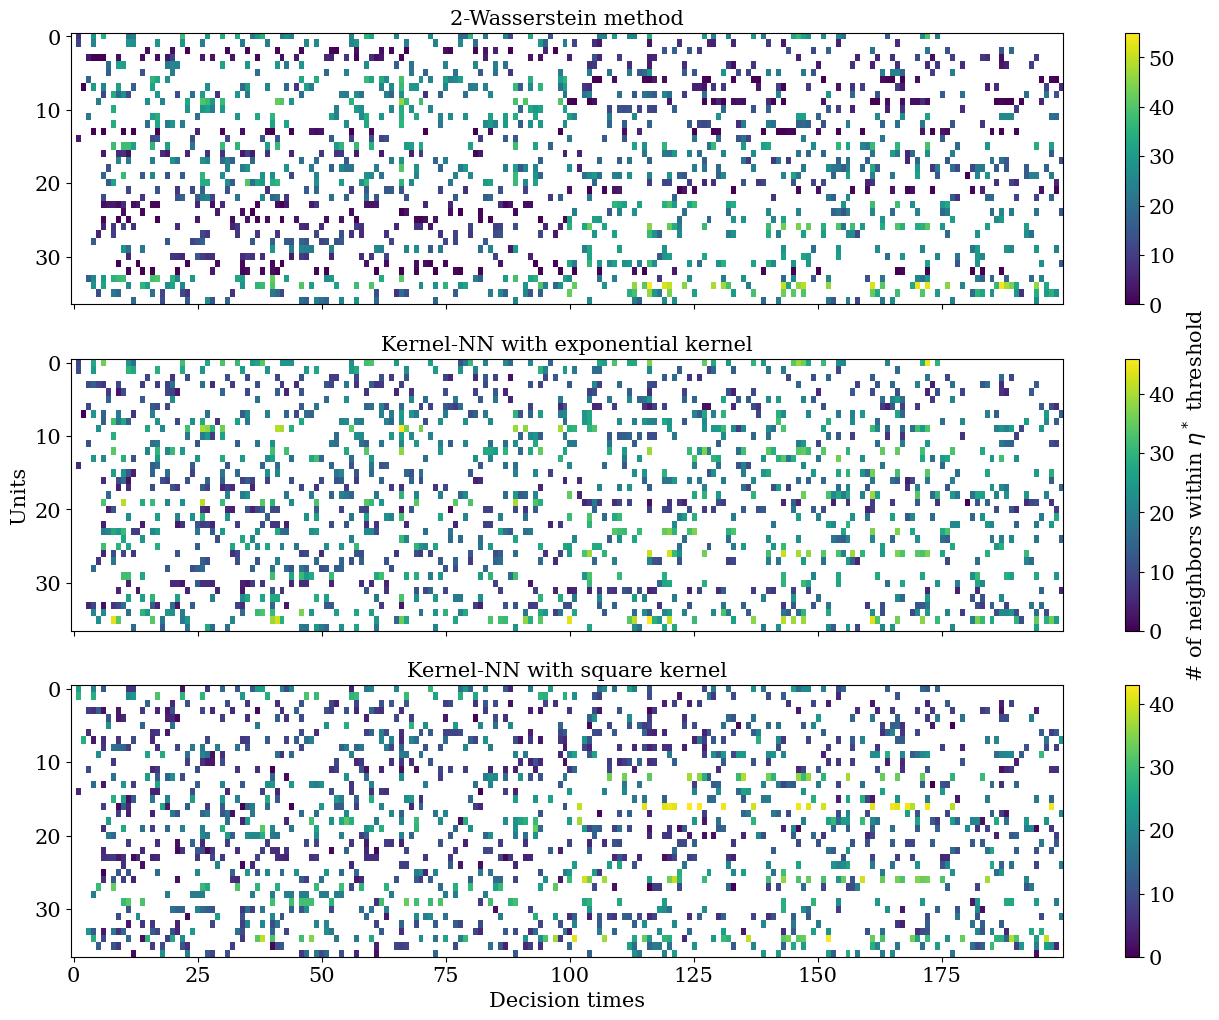

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize=(16, 12), nrows = 3)

pos1 = ax1.imshow(nn_ws2, aspect = 'auto')
pos2 = ax2.imshow(nn_mmd_exp, aspect = 'auto')
pos3 = ax3.imshow(nn_mmd_sq, aspect = 'auto')

fig.colorbar(pos1, ax = ax1)
fig.colorbar(pos2, ax = ax2, label = "# of neighbors within $\eta^*$ threshold")
fig.colorbar(pos3, ax = ax3)

ax3.set_xlabel("Decision times")
ax2.set_ylabel("Units")

ax1.get_xaxis().set_ticklabels([])
ax2.get_xaxis().set_ticklabels([])

ax1.set_title("2-Wasserstein method")
ax2.set_title("Kernel-NN with exponential kernel")
ax3.set_title("Kernel-NN with square kernel")

#fig.suptitle("2-sample Kolmogorov-Smirnov test statistic by DNN method")
plt.savefig("nn_density.pdf", bbox_inches = "tight")

In [ ]:
neighbor_bounds_10 = np.nonzero((nn_ws2 > 10) & (nn_mmd_exp > 10) & (nn_mmd_sq > 10))
neighbor_bounds_5 = np.nonzero((nn_ws2 > 5) & (nn_mmd_exp > 5) & (nn_mmd_sq > 5))


In [ ]:
import seaborn as sns

In [ ]:
# filter neighbors
nn5_mmd_sq_log_mean = squared_error_mmd_sq_log_mean[neighbor_bounds_5]
nn5_mmd_exp_log_mean = squared_error_mmd_exp_log_mean[neighbor_bounds_5]
nn5_ws2_log_mean = squared_error_ws2_log_mean[neighbor_bounds_5]

nn5_softimpute_log_mean = squared_error_softimpute_log_mean[neighbor_bounds_5]
nn5_usvt_log_mean = squared_error_usvt_log_mean[neighbor_bounds_5]
print(len(nn5_usvt_log_mean))

plots_filtered_5 = np.array([nn5_mmd_sq_log_mean, nn5_mmd_exp_log_mean, 
nn5_ws2_log_mean, nn5_softimpute_log_mean, nn5_usvt_log_mean])

986


In [ ]:
nn10_mmd_sq_log_mean = squared_error_mmd_sq_log_mean[neighbor_bounds_10]
nn10_mmd_exp_log_mean = squared_error_mmd_exp_log_mean[neighbor_bounds_10]
nn10_ws2_log_mean = squared_error_ws2_log_mean[neighbor_bounds_10]

nn10_softimpute_log_mean = squared_error_softimpute_log_mean[neighbor_bounds_10]
nn10_usvt_log_mean = squared_error_usvt_log_mean[neighbor_bounds_10]
print(len(nn10_usvt_log_mean))

plots_filtered_10 = np.array([nn10_mmd_sq_log_mean, nn10_mmd_exp_log_mean, 
nn10_ws2_log_mean, nn10_softimpute_log_mean, nn10_usvt_log_mean])

599


In [ ]:
plots_filtered_10.shape

(5, 599)

In [1154]:
# all neighbors
mean_plots = np.array([squared_error_mmd_sq_log_mean.flatten(),  
squared_error_mmd_exp_log_mean.flatten(),
squared_error_ws2_log_mean.flatten(),
squared_error_softimpute_log_mean.flatten(), 
squared_error_usvt_log_mean.flatten()])

abs_mean_plots = np.array([abs_error_mmd_sq_log_mean.flatten(),  
abs_error_mmd_exp_log_mean.flatten(),
abs_error_ws2_log_mean.flatten(),
abs_error_snn_log_mean.flatten(),
abs_error_softimpute_log_mean.flatten(), 
abs_error_usvt_log_mean.flatten()])

In [1155]:
std_plots = np.array([squared_error_mmd_sq_log_std.flatten(),  
squared_error_mmd_exp_log_std.flatten(),
squared_error_ws2_log_std.flatten(),
squared_error_softimpute_log_std.flatten(), 
squared_error_usvt_log_std.flatten()])

abs_std_plots = np.array([abs_error_mmd_sq_log_std.flatten(),  
abs_error_mmd_exp_log_std.flatten(),
abs_error_ws2_log_std.flatten(),
abs_error_snn_log_std.flatten(),
abs_error_softimpute_log_std.flatten(), 
abs_error_usvt_log_std.flatten()])

In [1156]:
var_plots = np.array([squared_error_mmd_sq_log_var.flatten(),  
squared_error_mmd_exp_log_var.flatten(),
squared_error_ws2_log_var.flatten(),
squared_error_softimpute_log_var.flatten(), 
squared_error_usvt_log_var.flatten()])

abs_var_plots = np.array([abs_error_mmd_sq_log_var.flatten(),  
abs_error_mmd_exp_log_var.flatten(),
abs_error_ws2_log_var.flatten(),
abs_error_snn_log_var.flatten(),
abs_error_softimpute_log_var.flatten(), 
abs_error_usvt_log_var.flatten()])

In [1157]:
max_plots = np.array([squared_error_mmd_sq_log_max.flatten(),  
squared_error_mmd_exp_log_max.flatten(),
squared_error_ws2_log_max.flatten(),
squared_error_softimpute_log_max.flatten(), 
squared_error_usvt_log_max.flatten()])

abs_max_plots = np.array([abs_error_mmd_sq_log_max.flatten(),  
abs_error_mmd_exp_log_max.flatten(),
abs_error_ws2_log_max.flatten(),
abs_error_snn_log_max.flatten(),
abs_error_softimpute_log_max.flatten(), 
abs_error_usvt_log_max.flatten()])

In [1158]:
median_plots = np.array([squared_error_mmd_sq_log_median.flatten(),  
squared_error_mmd_exp_log_median.flatten(),
squared_error_ws2_log_median.flatten(),
squared_error_softimpute_log_median.flatten(), 
squared_error_usvt_log_median.flatten()])

abs_median_plots = np.array([abs_error_mmd_sq_log_median.flatten(),  
abs_error_mmd_exp_log_median.flatten(),
abs_error_ws2_log_median.flatten(),
abs_error_snn_log_median.flatten(),
abs_error_softimpute_log_median.flatten(), 
abs_error_usvt_log_median.flatten()])

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\3786899853.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\3786899853.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels, rotation = 45, ha = 'right')


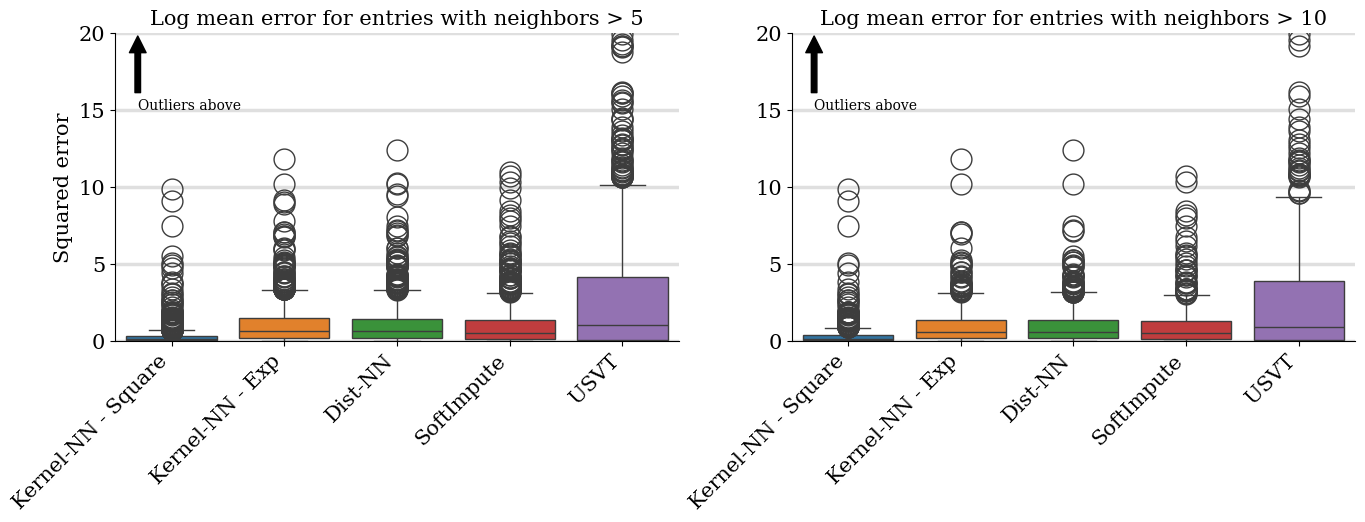

In [ ]:
#ax = plt.gca()

fig, (ax1, ax2) = plt.subplots(figsize = (16, 4), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)

labels = ["Kernel-NN - Square", "Kernel-NN - Exp", "Dist-NN", "SoftImpute", "USVT"]

sns.boxplot(plots_filtered_5.T, ax = ax1)
sns.boxplot(plots_filtered_10.T, ax = ax2)
ax1.set_ylim([0, 20])
ax2.set_ylim([0, 20])
ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
ax2.set_xticklabels(labels, rotation = 45, ha = 'right')

ax1.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
             arrowprops=dict(facecolor='black', shrink=0.05),
             )
ax2.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
  arrowprops=dict(facecolor='black', shrink=0.05),
  )
ax1.set_title("Log mean error for entries with neighbors > 5")
ax2.set_title("Log mean error for entries with neighbors > 10")

ax1.set_ylabel("Squared error")

plt.savefig("logmean_error.pdf", bbox_inches = "tight")

In [ ]:
np.count_nonzero(M_hs_log_median[A_hs == 1] != -1 )

1485

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1370698175.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1370698175.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels, rotation = 45, ha = 'right')


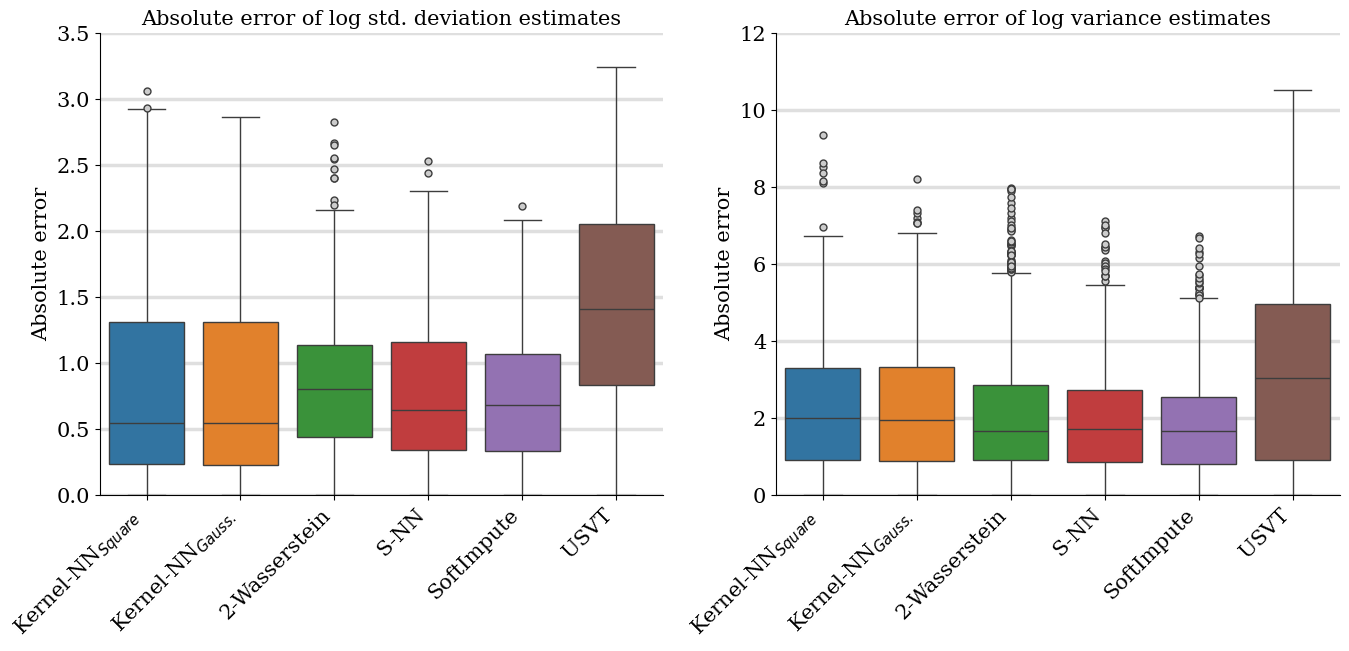

In [1183]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2, sharey = False)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)

# axs[1][0].spines['top'].set_visible(False)
# axs[1][0].spines['right'].set_visible(False)
# axs[1][0].grid(True, alpha=0.4)

# axs[1][1].spines['top'].set_visible(False)
# axs[1][1].spines['right'].set_visible(False)
# axs[1][1].grid(True, alpha=0.4)

labels = ["Kernel-NN$_{Square}$", "Kernel-NN$_{Gauss.}$", "2-Wasserstein", "S-NN", "SoftImpute", "USVT"]

flierprops = dict(markerfacecolor='0.8', markersize=5,
              linestyle='none')

ax1 = sns.boxplot(abs_std_plots.T, flierprops = flierprops, ax = ax1)
ax2 = sns.boxplot(abs_var_plots.T, flierprops = flierprops, ax = ax2)
# axs[1][0] = sns.boxplot(abs_var_plots.T, flierprops = flierprops, ax = axs[1][0])
# axs[1][1] = sns.boxplot(abs_std_plots.T, flierprops = flierprops, ax = axs[1][1])

ax1.set_ylim([0, 3.5])
ax2.set_ylim([0, 12])
#axs[0][0].set_xticklabels(labels, rotation = 45, ha = 'right')
#axs[0][1].set_xticklabels(labels, rotation = 45, ha = 'right')
ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
ax2.set_xticklabels(labels, rotation = 45, ha = 'right')

# plt.annotate('Outliers above', xy=(3.7, 17500), xytext=(3.7, 14000),
#              arrowprops=dict(facecolor='black', shrink=0.05), ha = "center"
#              )
ax1.set_title("Absolute error of log std. deviation estimates")
ax2.set_title("Absolute error of log variance estimates")

ax1.set_ylabel("Absolute error")
ax2.set_ylabel("Absolute error")

plt.savefig("abs_logvar_std_error.pdf", bbox_inches = "tight")

In [ ]:
ws2_col_diffs = np

In [ ]:
np.count_nonzero(~np.isnan(mmd_exp_log_median))

1485

In [ ]:
pd.DataFrame(M_hs_log_median - mmd_sq_log_median)

,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
0,NaN,-3.177185,NaN,NaN,1.228368,NaN,0.486725,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,0.505905,0.180345,0.000000,1.159257,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,...,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,-0.255413,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,2.948577,0.000000,NaN
7,NaN,NaN,0.0,NaN,0.860720,NaN,2.463627,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.032269,NaN,NaN,0.0
8,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,...,NaN,NaN,0.0,NaN,NaN,NaN,0.000000,NaN,2.944439,NaN
9,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,0.153263,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN


In [ ]:
pd.DataFrame(mmd_sq_log_median)

,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
0,NaN,3.177185,NaN,NaN,0.549306,NaN,3.526361,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,4.769390,4.663439,0.0,4.848109,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,...,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.921924,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.000000,0.000000,NaN
7,NaN,NaN,0.0,NaN,4.473187,NaN,1.416607,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,3.39897,NaN,NaN,0.0
8,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.0,0.000000,...,NaN,NaN,0.0,NaN,NaN,NaN,0.00000,NaN,0.000000,NaN
9,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,3.156774,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN


## Comparing performance for non-log transformed data

In [1197]:
# set up
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")
M_hs_reg = np.load("../data_checkpoints/heartsteps_data.npy")

# required for Wasserstein
M_hs_reg = np.sort(M_hs_reg, axis = -1)

# dimension of the data is 1
M_hs_reg = M_hs_reg[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs_reg = M_hs_reg[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs_reg.shape

In [1210]:
mmd_estimates_exp_reg = np.load("../data_checkpoints/mmd_exp_estimates_v12.npy", allow_pickle = True)
mmd_estimates_sq_reg = np.load("../data_checkpoints/mmd_sq_estimates_v12.npy", allow_pickle = True)
ws2_estimates_reg = np.load("../data_checkpoints/ws2_estimates_v12.npy")

nn_ws2_reg = np.load('../data_checkpoints/ws2_nncount_v12.npy')
nn_mmd_exp_reg = np.load('../data_checkpoints/mmd_exp_nncount_v12.npy')
nn_mmd_sq_reg = np.load('../data_checkpoints/mmd_sq_nncount_v12.npy')

In [ ]:
# mean m_hs
M_hs_reg_mean = np.nanmean(M_hs_reg.squeeze(), axis = 2)

#M_hs_log_mean = np.mean(np.log(M_hs.squeeze() + 1), axis = 2)

# std dev M_hs
M_hs_reg_std = np.nanstd(M_hs_reg.squeeze(), axis = 2)
#M_hs_log_std = np.std(np.log(M_hs.squeeze() + 1), axis = 2)

# variance
M_hs_reg_var = np.nanvar(M_hs_reg.squeeze(), axis = 2)
# M_hs_log_var = np.var(np.log(M_hs.squeeze() + 1), axis = 2)

# max
M_hs_reg_max = np.nanmax(M_hs_reg.squeeze(), axis = 2)
#M_hs_log_max = np.max(np.log(M_hs.squeeze() + 1), axis = 2)

# median
M_hs_reg_median = np.nanmedian(M_hs_reg.squeeze(), axis = 2)
#M_hs_log_median = np.median(np.log(M_hs.squeeze() + 1), axis = 2)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1432203240.py:2: RuntimeWarning: Mean of empty slice
  M_hs_reg_mean = np.nanmean(M_hs_reg.squeeze(), axis = 2)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1432203240.py:11: RuntimeWarning: Degrees of freedom <= 0 for slice.
  M_hs_reg_var = np.nanvar(M_hs_reg.squeeze(), axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1432203240.py:15: RuntimeWarning: All-NaN slice encountered
  M_hs_reg_max = np.nanmax(M_hs_reg.squeeze(), axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1432203240.py:19: RuntimeWarning: All-NaN slice encountered
  M_hs_reg_median = np.nanmedian(M_hs_reg.squeeze(), axis = 2)


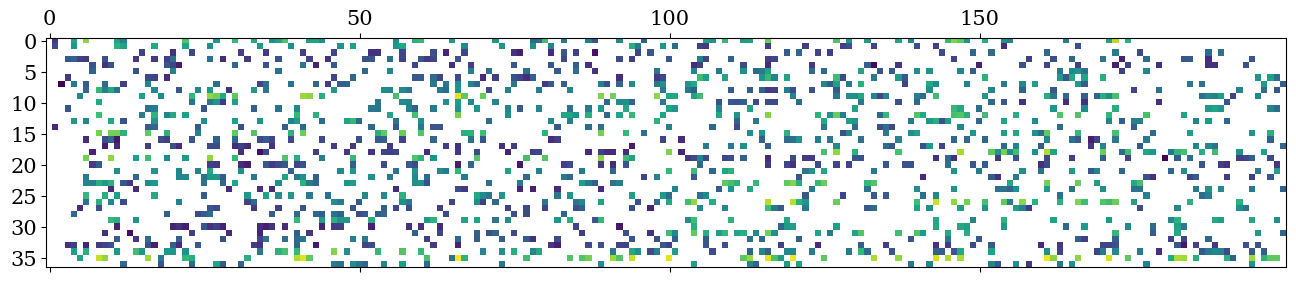

In [ ]:
matshow(nn_mmd_exp_reg, aspect = 'auto')

In [ ]:
M_hat_softimpute_reg_mean = scaler_methods.test_estimate_softimpute(M_hs_reg_mean, A_hs)
M_hat_softimpute_reg_std = scaler_methods.test_estimate_softimpute(M_hs_reg_std, A_hs)
M_hat_softimpute_reg_var = scaler_methods.test_estimate_softimpute(M_hs_reg_var, A_hs)
M_hat_softimpute_reg_max = scaler_methods.test_estimate_softimpute(M_hs_reg_max, A_hs)
M_hat_softimpute_reg_median = scaler_methods.test_estimate_softimpute(M_hs_reg_median, A_hs)

Imputation #0 out of 1485
Imputation #1 out of 1485
Imputation #2 out of 1485
Imputation #3 out of 1485
Imputation #4 out of 1485
Imputation #5 out of 1485
Imputation #6 out of 1485
Imputation #7 out of 1485
Imputation #8 out of 1485
Imputation #9 out of 1485
Imputation #10 out of 1485
Imputation #11 out of 1485
Imputation #12 out of 1485
Imputation #13 out of 1485
Imputation #14 out of 1485
Imputation #15 out of 1485
Imputation #16 out of 1485
Imputation #17 out of 1485
Imputation #18 out of 1485
Imputation #19 out of 1485
Imputation #20 out of 1485
Imputation #21 out of 1485
Imputation #22 out of 1485
Imputation #23 out of 1485
Imputation #24 out of 1485
Imputation #25 out of 1485
Imputation #26 out of 1485
Imputation #27 out of 1485
Imputation #28 out of 1485
Imputation #29 out of 1485
Imputation #30 out of 1485
Imputation #31 out of 1485
Imputation #32 out of 1485
Imputation #33 out of 1485
Imputation #34 out of 1485
Imputation #35 out of 1485
Imputation #36 out of 1485
Imputation 

In [ ]:
M_hat_usvt_reg_mean = scaler_methods.test_estimate_usvt(M_hs_reg_mean, A_hs)
M_hat_usvt_reg_std = scaler_methods.test_estimate_usvt(M_hs_reg_std, A_hs)
M_hat_usvt_reg_var = scaler_methods.test_estimate_usvt(M_hs_reg_var, A_hs)
M_hat_usvt_reg_max = scaler_methods.test_estimate_usvt(M_hs_reg_max, A_hs)
M_hat_usvt_reg_median = scaler_methods.test_estimate_usvt(M_hs_reg_median, A_hs)

Imputation #0 out of 1485
Imputation #1 out of 1485
Imputation #2 out of 1485
Imputation #3 out of 1485
Imputation #4 out of 1485
Imputation #5 out of 1485
Imputation #6 out of 1485
Imputation #7 out of 1485
Imputation #8 out of 1485
Imputation #9 out of 1485
Imputation #10 out of 1485
Imputation #11 out of 1485
Imputation #12 out of 1485
Imputation #13 out of 1485
Imputation #14 out of 1485
Imputation #15 out of 1485
Imputation #16 out of 1485
Imputation #17 out of 1485
Imputation #18 out of 1485
Imputation #19 out of 1485
Imputation #20 out of 1485
Imputation #21 out of 1485
Imputation #22 out of 1485
Imputation #23 out of 1485
Imputation #24 out of 1485
Imputation #25 out of 1485
Imputation #26 out of 1485
Imputation #27 out of 1485
Imputation #28 out of 1485
Imputation #29 out of 1485
Imputation #30 out of 1485
Imputation #31 out of 1485
Imputation #32 out of 1485
Imputation #33 out of 1485
Imputation #34 out of 1485
Imputation #35 out of 1485
Imputation #36 out of 1485
Imputation 

In [ ]:
squared_error_softimpute_reg_mean = (M_hs_reg_mean - M_hat_softimpute_reg_mean)**2 
squared_error_softimpute_reg_std = (M_hs_reg_std - M_hat_softimpute_reg_std) ** 2
squared_error_softimpute_reg_var = (M_hs_reg_var - M_hat_softimpute_reg_var) ** 2
squared_error_softimpute_reg_max = (M_hs_reg_max - M_hat_softimpute_reg_max) ** 2
squared_error_softimpute_reg_median = (M_hs_reg_median - M_hat_softimpute_reg_median) ** 2

abs_error_softimpute_reg_mean = abs(M_hs_reg_mean - M_hat_softimpute_reg_mean) 
abs_error_softimpute_reg_std = abs(M_hs_reg_std - M_hat_softimpute_reg_std)
abs_error_softimpute_reg_var = abs(M_hs_reg_var - M_hat_softimpute_reg_var)
abs_error_softimpute_reg_max = abs(M_hs_reg_max - M_hat_softimpute_reg_max)
abs_error_softimpute_reg_median = abs(M_hs_reg_median - M_hat_softimpute_reg_median)

np.float64(0.0012180859892474416)

In [ ]:
squared_error_usvt_reg_mean = (M_hs_reg_mean - M_hat_usvt_reg_mean)**2 
squared_error_usvt_reg_std = (M_hs_reg_std - M_hat_usvt_reg_std)**2 
squared_error_usvt_reg_var = (M_hs_reg_var - M_hat_usvt_reg_var)**2 
squared_error_usvt_reg_max = (M_hs_reg_max - M_hat_usvt_reg_max)**2 
squared_error_usvt_reg_median = (M_hs_reg_median - M_hat_usvt_reg_median)**2

abs_error_usvt_reg_mean = abs(M_hs_reg_mean - M_hat_usvt_reg_mean)
abs_error_usvt_reg_std = abs(M_hs_reg_std - M_hat_usvt_reg_std)
abs_error_usvt_reg_var = abs(M_hs_reg_var - M_hat_usvt_reg_var)
abs_error_usvt_reg_max = abs(M_hs_reg_max - M_hat_usvt_reg_max)
abs_error_usvt_reg_median = abs(M_hs_reg_median - M_hat_usvt_reg_median)

In [1211]:
ws2_reg_mean = np.nanmean(ws2_estimates_reg, axis = 2)
ws2_reg_std = np.nanstd(ws2_estimates_reg, axis = 2)
ws2_reg_var = np.nanvar(ws2_estimates_reg, axis = 2)
ws2_reg_max = np.nanmax(ws2_estimates_reg, axis = 2)
ws2_reg_median = np.nanmedian(ws2_estimates_reg, axis = 2)

squared_error_ws2_reg_mean = (M_hs_reg_mean - ws2_reg_mean)**2  
squared_error_ws2_reg_std = (M_hs_reg_std - ws2_reg_std) ** 2
squared_error_ws2_reg_var = (M_hs_reg_var - ws2_reg_var) ** 2
squared_error_ws2_reg_max = (M_hs_reg_max - ws2_reg_max) ** 2
squared_error_ws2_reg_median = (M_hs_reg_median - ws2_reg_median) ** 2

abs_error_ws2_reg_mean = abs(M_hs_reg_mean - ws2_reg_mean)  
abs_error_ws2_reg_std = abs(M_hs_reg_std - ws2_reg_std)
abs_error_ws2_reg_var = abs(M_hs_reg_var - ws2_reg_var)
abs_error_ws2_reg_max = abs(M_hs_reg_max - ws2_reg_max)
abs_error_ws2_reg_median = abs(M_hs_reg_median - ws2_reg_median)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\263543820.py:1: RuntimeWarning: Mean of empty slice
  ws2_reg_mean = np.nanmean(ws2_estimates_reg, axis = 2)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\263543820.py:3: RuntimeWarning: Degrees of freedom <= 0 for slice.
  ws2_reg_var = np.nanvar(ws2_estimates_reg, axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\263543820.py:4: RuntimeWarning: All-NaN slice encountered
  ws2_reg_max = np.nanmax(ws2_estimates_reg, axis = 2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\263543820.py:5: RuntimeWarning: All-NaN slice encountered
  ws2_reg_median = np.nanmedian(ws2_estimates_reg, axis = 2)


In [1212]:
nans = 0
mmd_exp_reg_mean = np.full([N, T], np.nan)
mmd_exp_reg_std = np.full([N, T], np.nan)
mmd_exp_reg_var = np.full([N, T], np.nan)
mmd_exp_reg_max = np.full([N, T], np.nan)
mmd_exp_reg_median = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):

    if mmd_estimates_exp_reg[i][j] is None:
      continue
    mmd_exp_reg_mean[i, j] = np.nanmean(mmd_estimates_exp_reg[i][j])
    mmd_exp_reg_std[i, j] = np.nanstd(mmd_estimates_exp_reg[i][j])
    mmd_exp_reg_var[i, j] = np.nanvar(mmd_estimates_exp_reg[i][j])
    mmd_exp_reg_max[i, j] = np.nanmax(mmd_estimates_exp_reg[i][j])
    mmd_exp_reg_median[i, j] = np.nanmedian(mmd_estimates_exp_reg[i][j])

In [1213]:
squared_error_mmd_exp_reg_mean = (M_hs_reg_mean - mmd_exp_reg_mean)**2
squared_error_mmd_exp_reg_std = (M_hs_reg_std - mmd_exp_reg_std)**2
squared_error_mmd_exp_reg_var = (M_hs_reg_var - mmd_exp_reg_var)**2
squared_error_mmd_exp_reg_max = (M_hs_reg_max - mmd_exp_reg_max)**2
squared_error_mmd_exp_reg_median = (M_hs_reg_median - mmd_exp_reg_median)**2

abs_error_mmd_exp_reg_mean = abs(M_hs_reg_mean - mmd_exp_reg_mean)
abs_error_mmd_exp_reg_std = abs(M_hs_reg_std - mmd_exp_reg_std)
abs_error_mmd_exp_reg_var = abs(M_hs_reg_var - mmd_exp_reg_var)
abs_error_mmd_exp_reg_max = abs(M_hs_reg_max - mmd_exp_reg_max)
abs_error_mmd_exp_reg_median = abs(M_hs_reg_median - mmd_exp_reg_median)

In [1214]:
nans = 0
mmd_sq_reg_mean = np.full([N, T], np.nan)
mmd_sq_reg_std = np.full([N, T], np.nan)
mmd_sq_reg_var = np.full([N, T], np.nan)
mmd_sq_reg_max = np.full([N, T], np.nan)
mmd_sq_reg_median = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    if mmd_estimates_sq_reg[i][j] is None:
      continue
    mmd_sq_reg_mean[i, j] = np.nanmean(mmd_estimates_sq_reg[i][j])
    mmd_sq_reg_std[i, j] = np.nanstd(mmd_estimates_sq_reg[i][j])
    mmd_sq_reg_var[i, j] = np.nanvar(mmd_estimates_sq_reg[i][j])
    mmd_sq_reg_max[i, j] = np.nanmax(mmd_estimates_sq_reg[i][j])
    mmd_sq_reg_median[i, j] = np.nanmedian(mmd_estimates_sq_reg[i][j])

In [1215]:
squared_error_mmd_sq_reg_mean = (M_hs_reg_mean - mmd_sq_reg_mean)**2
squared_error_mmd_sq_reg_std = (M_hs_reg_std - mmd_sq_reg_std)**2
squared_error_mmd_sq_reg_var = (M_hs_reg_var - mmd_sq_reg_var)**2
squared_error_mmd_sq_reg_max = (M_hs_reg_max - mmd_sq_reg_max)**2
squared_error_mmd_sq_reg_median = (M_hs_reg_median - mmd_sq_reg_median)**2

abs_error_mmd_sq_reg_mean = abs(M_hs_reg_mean - mmd_sq_reg_mean)
abs_error_mmd_sq_reg_std = abs(M_hs_reg_std - mmd_sq_reg_std)
abs_error_mmd_sq_reg_var = abs(M_hs_reg_var - mmd_sq_reg_var)
abs_error_mmd_sq_reg_max = abs(M_hs_reg_max - mmd_sq_reg_max)
abs_error_mmd_sq_reg_median = abs(M_hs_reg_median - mmd_sq_reg_median)

In [1244]:
mask = (nn_mmd_exp > 15) & (nn_mmd_sq > 20) & (nn_ws2 > 20)
mask

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ...,  True,  True, False],
       [False, False, False, ..., False, False, False]])

In [1245]:
# all neighbors
reg_mean_plots = np.array([squared_error_mmd_sq_reg_mean.flatten(),  
squared_error_mmd_exp_reg_mean.flatten(),
squared_error_ws2_reg_mean.flatten(),
squared_error_softimpute_reg_mean.flatten(), 
squared_error_usvt_reg_mean.flatten()])

abs_reg_mean_plots = np.array([abs_error_mmd_sq_reg_mean.flatten(),  
abs_error_mmd_exp_reg_mean.flatten(),
abs_error_ws2_reg_mean.flatten(),
abs_error_snn_mean.flatten(),
abs_error_softimpute_reg_mean.flatten(), 
abs_error_usvt_reg_mean.flatten()])

masked_abs_reg_mean_plots =  np.array([abs_error_mmd_sq_reg_mean[mask].flatten(),  
abs_error_mmd_exp_reg_mean[mask].flatten(),
abs_error_ws2_reg_mean[mask].flatten(),
abs_error_snn_mean[mask].flatten(),
abs_error_softimpute_reg_mean[mask].flatten(), 
abs_error_usvt_reg_mean[mask].flatten()])

In [1247]:
reg_std_plots = np.array([squared_error_mmd_sq_reg_std.flatten(),  
squared_error_mmd_exp_reg_std.flatten(),
squared_error_ws2_reg_std.flatten(),
squared_error_softimpute_reg_std.flatten(), 
squared_error_usvt_reg_std.flatten()])

abs_reg_std_plots = np.array([abs_error_mmd_sq_reg_std.flatten(),  
abs_error_mmd_exp_reg_std.flatten(),
abs_error_ws2_reg_std.flatten(),
abs_error_snn_std.flatten(),
abs_error_softimpute_reg_std.flatten(), 
abs_error_usvt_reg_std.flatten()])

masked_abs_reg_std_plots = np.array([abs_error_mmd_sq_reg_std[mask].flatten(),  
abs_error_mmd_exp_reg_std[mask].flatten(),
abs_error_ws2_reg_std[mask].flatten(),
abs_error_snn_std[mask].flatten(),
abs_error_softimpute_reg_std[mask].flatten(), 
abs_error_usvt_reg_std[mask].flatten()])

In [1248]:
reg_var_plots = np.array([squared_error_mmd_sq_reg_var.flatten(),  
squared_error_mmd_exp_reg_var.flatten(),
squared_error_ws2_reg_var.flatten(),
squared_error_softimpute_reg_var.flatten(), 
squared_error_usvt_reg_var.flatten()])

abs_reg_var_plots = np.array([abs_error_mmd_sq_reg_var.flatten(),  
abs_error_mmd_exp_reg_var.flatten(),
abs_error_ws2_reg_var.flatten(),
abs_error_snn_var.flatten(),
abs_error_softimpute_reg_var.flatten(), 
abs_error_usvt_reg_var.flatten()])

masked_abs_reg_var_plots = np.array([abs_error_mmd_sq_reg_var[mask].flatten(),  
abs_error_mmd_exp_reg_var[mask].flatten(),
abs_error_ws2_reg_var[mask].flatten(),
abs_error_snn_var[mask].flatten(),
abs_error_softimpute_reg_var[mask].flatten(), 
abs_error_usvt_reg_var[mask].flatten()])

In [1249]:
reg_max_plots = np.array([squared_error_mmd_sq_reg_max.flatten(),  
squared_error_mmd_exp_reg_max.flatten(),
squared_error_ws2_reg_max.flatten(),
squared_error_softimpute_reg_max.flatten(), 
squared_error_usvt_reg_max.flatten()])

abs_reg_max_plots = np.array([abs_error_mmd_sq_reg_max.flatten(),  
abs_error_mmd_exp_reg_max.flatten(),
abs_error_ws2_reg_max.flatten(),
abs_error_snn_max.flatten(),
abs_error_softimpute_reg_max.flatten(), 
abs_error_usvt_reg_max.flatten()])

masked_abs_reg_max_plots = np.array([abs_error_mmd_sq_reg_max[mask].flatten(),  
abs_error_mmd_exp_reg_max[mask].flatten(),
abs_error_ws2_reg_max[mask].flatten(),
abs_error_snn_max[mask].flatten(),
abs_error_softimpute_reg_max[mask].flatten(), 
abs_error_usvt_reg_max[mask].flatten()])

In [1256]:
reg_median_plots = np.array([squared_error_mmd_sq_reg_median.flatten(),  
squared_error_mmd_exp_reg_median.flatten(),
squared_error_ws2_reg_median.flatten(),
squared_error_softimpute_reg_median.flatten(), 
squared_error_usvt_reg_median.flatten()])

abs_reg_median_plots = np.array([abs_error_mmd_sq_reg_median.flatten(),  
abs_error_mmd_exp_reg_median.flatten(),
abs_error_ws2_reg_median.flatten(),
abs_error_snn_median.flatten(),
abs_error_softimpute_reg_median.flatten(), 
abs_error_usvt_reg_median.flatten()])

masked_abs_reg_median_plots = np.array([abs_error_mmd_sq_reg_median[mask].flatten(),  
abs_error_mmd_exp_reg_median[mask].flatten(),
abs_error_ws2_reg_median[mask].flatten(),
abs_error_snn_median[mask].flatten(),
abs_error_softimpute_reg_median[mask].flatten(), 
abs_error_usvt_reg_median[mask].flatten()])

C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1767025854.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
C:\Users\Caleb\AppData\Local\Temp\ipykernel_25008\1767025854.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels, rotation = 45, ha = 'right')


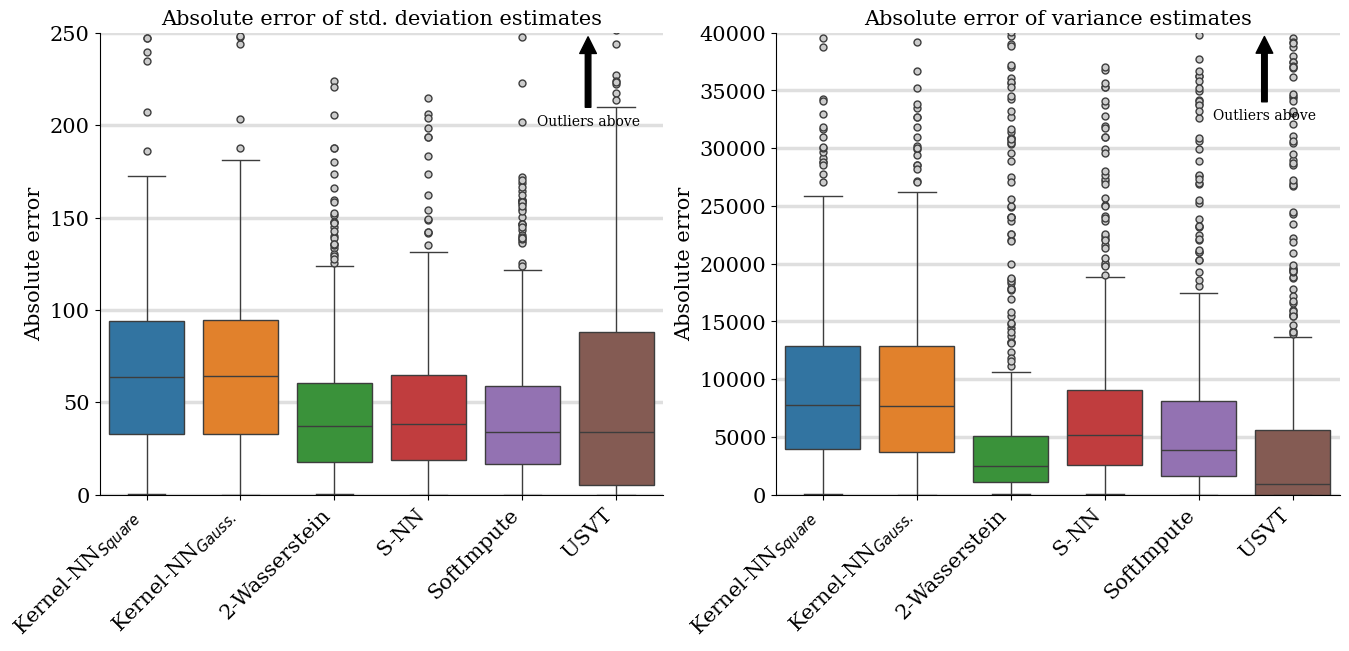

In [1275]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2, sharey = False)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)

# axs[1][0].spines['top'].set_visible(False)
# axs[1][0].spines['right'].set_visible(False)
# axs[1][0].grid(True, alpha=0.4)

# axs[1][1].spines['top'].set_visible(False)
# axs[1][1].spines['right'].set_visible(False)
# axs[1][1].grid(True, alpha=0.4)

labels = ["Kernel-NN$_{Square}$", "Kernel-NN$_{Gauss.}$", "2-Wasserstein", "S-NN", "SoftImpute", "USVT"]

flierprops = dict(markerfacecolor='0.8', markersize=5,
              linestyle='none')

ax1 = sns.boxplot(masked_abs_reg_std_plots.T, flierprops = flierprops, ax = ax1)
ax2 = sns.boxplot(masked_abs_reg_var_plots.T, flierprops = flierprops, ax = ax2)
# axs[1][0] = sns.boxplot(abs_var_plots.T, flierprops = flierprops, ax = axs[1][0])
# axs[1][1] = sns.boxplot(abs_std_plots.T, flierprops = flierprops, ax = axs[1][1])

ax1.set_ylim([0, 250])
ax2.set_ylim([0, 40000])
#axs[0][0].set_xticklabels(labels, rotation = 45, ha = 'right')
#axs[0][1].set_xticklabels(labels, rotation = 45, ha = 'right')
ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
ax2.set_xticklabels(labels, rotation = 45, ha = 'right')

ax1.annotate('Outliers above', xy=(4.7, 250), xytext=(4.7, 200),
             arrowprops=dict(facecolor='black', shrink=0.05), ha = "center"
              )

ax2.annotate('Outliers above', xy=(4.7, 40000), xytext=(4.7, 32500),
arrowprops=dict(facecolor='black', shrink=0.05), ha = "center"
)
ax1.set_title("Absolute error of std. deviation estimates")
ax2.set_title("Absolute error of variance estimates")

ax1.set_ylabel("Absolute error")
ax2.set_ylabel("Absolute error")

plt.savefig("abs_regstd_var_error.pdf", bbox_inches = "tight")

In [1288]:
# log mean estimate over time compared to ground truth

ws2_log_mean_estimate_unit0 = ws2_log_mean[33][A_hs[33] == 1]
log_mean_truth_unit0 = M_hs_log_mean[33][A_hs[33] == 1]

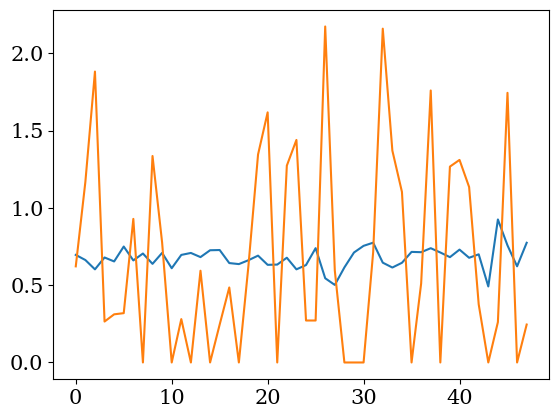

In [1289]:
plt.plot(ws2_log_mean_estimate_unit0)
plt.plot(log_mean_truth_unit0)

In [1297]:
mmd_exp_log_mean_estimate_unit0 = mmd_exp_log_mean[33][A_hs[33] == 1]

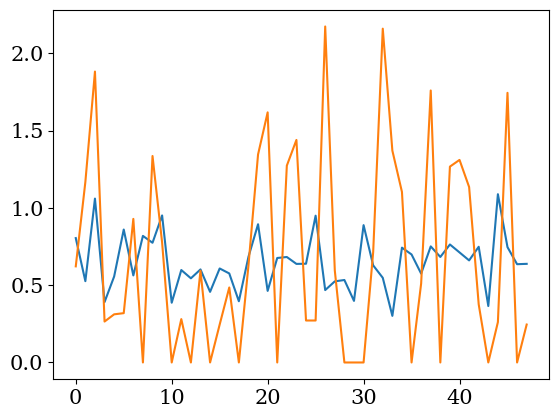

In [1298]:
plt.plot(mmd_exp_log_mean_estimate_unit0)
plt.plot(log_mean_truth_unit0)
